# ARG Prediction from Protein Sequence Composition
### Antibiotic Resistance Gene Classification | Cross-Database Generalization Study

**Pipeline:** Data Collection → Cleaning → Feature Engineering → Model Training → Cross-DB Evaluation → SHAP Interpretability

> **Instructions:** Run cells top to bottom. All outputs are saved to Google Drive after each major step — you can safely disconnect and resume from any checkpoint.


---
## Section 0 — Environment Setup
Install tools, mount Drive, create folder structure.

In [ ]:
# ── 0.1 Install system tools ──────────────────────────────────────────────────
import subprocess, sys

print("Installing system tools (CD-HIT, BLAST+)...")
subprocess.run(["apt-get", "install", "-y", "-q", "cd-hit", "ncbi-blast+"],
               capture_output=True)
print("✓ System tools installed")


Installing system tools (CD-HIT, BLAST+)...
✓ System tools installed


In [ ]:
# ── 0.2 Install Python packages ───────────────────────────────────────────────
import subprocess
pkgs = ["biopython", "requests", "pandas", "numpy",
        "scikit-learn", "xgboost", "shap",
        "matplotlib", "seaborn", "tqdm"]

print("Installing Python packages...")
subprocess.run([sys.executable, "-m", "pip", "install", "-q"] + pkgs,
               capture_output=True)
print("✓ Python packages installed")


Installing Python packages...
✓ Python packages installed


In [ ]:
# ── 0.3 Mount Google Drive ────────────────────────────────────────────────────
from google.colab import drive
drive.mount('/content/drive')
print("✓ Drive mounted")


Mounted at /content/drive
✓ Drive mounted


In [ ]:
# ── 0.4 Create folder structure ───────────────────────────────────────────────
import os

BASE = "/content/drive/MyDrive/ARG_Project"

dirs = [
    f"{BASE}/data/raw",
    f"{BASE}/data/processed",
    f"{BASE}/data/features",
    f"{BASE}/data/checkpoints",
    f"{BASE}/results/figures",
    f"{BASE}/results/tables",
    f"{BASE}/notebooks",
]

for d in dirs:
    os.makedirs(d, exist_ok=True)

print("✓ Folder structure created:")
for d in dirs:
    print(f"   {d}")


✓ Folder structure created:
   /content/drive/MyDrive/ARG_Project/data/raw
   /content/drive/MyDrive/ARG_Project/data/processed
   /content/drive/MyDrive/ARG_Project/data/features
   /content/drive/MyDrive/ARG_Project/data/checkpoints
   /content/drive/MyDrive/ARG_Project/results/figures
   /content/drive/MyDrive/ARG_Project/results/tables
   /content/drive/MyDrive/ARG_Project/notebooks


In [ ]:
# ── 0.5 Imports ───────────────────────────────────────────────────────────────
import os, re, hashlib, random, subprocess, json, time
from pathlib import Path
from collections import Counter
from itertools import product as iproduct

import numpy as np
import pandas as pd
import requests
from tqdm import tqdm

from Bio import SeqIO
from Bio.SeqUtils.ProtParam import ProteinAnalysis

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import (roc_auc_score, f1_score, matthews_corrcoef,
                             precision_recall_curve, average_precision_score,
                             confusion_matrix, roc_curve)
from sklearn.preprocessing import LabelEncoder

import xgboost as xgb
import shap

import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

# ── Global settings ────────────────────────────────────────────────────────────
SEED       = 42
N_SAMPLES  = 5000
BASE       = "/content/drive/MyDrive/ARG_Project"
RAW        = f"{BASE}/data/raw"
PROC       = f"{BASE}/data/processed"
FEAT       = f"{BASE}/data/features"
CKPT       = f"{BASE}/data/checkpoints"
FIGS       = f"{BASE}/results/figures"
TABS       = f"{BASE}/results/tables"

random.seed(SEED)
np.random.seed(SEED)

matplotlib.rcParams['figure.dpi'] = 150
sns.set_style("whitegrid")

print("✓ All imports successful")
print(f"  Base path : {BASE}")
print(f"  Seed      : {SEED}")
print(f"  N samples : {N_SAMPLES} per class")


✓ All imports successful
  Base path : /content/drive/MyDrive/ARG_Project
  Seed      : 42
  N samples : 5000 per class


---
## Section 1 — Data Collection
Download CARD positives, Swiss-Prot negatives, and ResFinder test sequences.

In [ ]:
# ── 1.1 Download CARD positive sequences ──────────────────────────────────────
CARD_RAW = f"{RAW}/card_positive_raw.fasta"

if os.path.exists(CARD_RAW):
    print(f"✓ CARD FASTA already downloaded: {CARD_RAW}")
else:
    CARD_URL = (
        "https://card.mcmaster.ca/latest/data"
        # We fetch the CARD protein homolog model FASTA
    )
    # Direct FASTA download from CARD
    CARD_FASTA_URL = "https://card.mcmaster.ca/download/0/broadstreet-v3.3.0.tar.bz2"
    # Note: CARD bundles sequences in a tarball — we wget and extract
    print("Downloading CARD data bundle...")
    subprocess.run(
        ["wget", "-q", "-O", f"{RAW}/card_data.tar.bz2", CARD_FASTA_URL],
        check=True
    )
    # Extract only the protein homolog FASTA
    subprocess.run(
        ["tar", "-xjf", f"{RAW}/card_data.tar.bz2",
         "-C", RAW,
         "--wildcards", "*.fasta"],
        check=False   # some tar versions use different flags; we handle below
    )
    # Find the extracted protein homolog fasta
    fasta_files = list(Path(RAW).glob("*protein_homolog_model*"))
    if not fasta_files:
        fasta_files = list(Path(RAW).glob("*.fasta"))
    if fasta_files:
        import shutil
        shutil.copy(str(fasta_files[0]), CARD_RAW)
        print(f"✓ CARD FASTA saved to {CARD_RAW}")
    else:
        print("⚠ Could not auto-extract. Please download manually from:")
        print("  https://card.mcmaster.ca/latest/data")
        print("  File: protein_fasta_protein_homolog_model.fasta")
        print(f"  Save to: {CARD_RAW}")


✓ CARD FASTA saved to /content/drive/MyDrive/ARG_Project/data/raw/card_positive_raw.fasta


In [ ]:
# ── 1.1b Manual fallback — if auto-download failed, run this cell ─────────────
# If the cell above printed a warning, download manually and re-run this cell.
# Otherwise skip.

CARD_DIRECT_URL = (
    "https://card.mcmaster.ca/latest/data/protein_fasta_protein_homolog_model.fasta"
)
if not os.path.exists(CARD_RAW):
    print("Attempting direct FASTA URL...")
    r = requests.get(CARD_DIRECT_URL, timeout=120)
    if r.status_code == 200:
        with open(CARD_RAW, "wb") as f:
            f.write(r.content)
        print(f"✓ CARD FASTA downloaded: {CARD_RAW}")
    else:
        print(f"✗ Failed (HTTP {r.status_code}). Manual download required.")
else:
    print(f"✓ CARD FASTA present: {CARD_RAW}")


✓ CARD FASTA present: /content/drive/MyDrive/ARG_Project/data/raw/card_positive_raw.fasta


In [ ]:
# ── 1.2 Parse and clean CARD sequences ────────────────────────────────────────
MIN_LEN, MAX_LEN = 50, 2000

def parse_and_filter(fasta_path, min_len=MIN_LEN, max_len=MAX_LEN):
    """Parse FASTA, filter by length, remove duplicates by sequence hash."""
    records = []
    seen_hashes = set()
    for rec in SeqIO.parse(fasta_path, "fasta"):
        seq = str(rec.seq).upper()
        # Remove sequences with non-standard amino acids
        if re.search(r'[^ACDEFGHIKLMNPQRSTVWY]', seq):
            continue
        if not (min_len <= len(seq) <= max_len):
            continue
        h = hashlib.md5(seq.encode()).hexdigest()
        if h in seen_hashes:
            continue
        seen_hashes.add(h)
        records.append(rec)
    return records

card_all = parse_and_filter(CARD_RAW)
print(f"CARD: {len(card_all)} sequences after length filter + deduplication")

# Sample N_SAMPLES
if len(card_all) > N_SAMPLES:
    random.seed(SEED)
    card_sampled = random.sample(card_all, N_SAMPLES)
else:
    card_sampled = card_all
    print(f"  ⚠ Only {len(card_all)} CARD sequences available (target: {N_SAMPLES})")

CARD_5K = f"{RAW}/card_positive_5000.fasta"
SeqIO.write(card_sampled, CARD_5K, "fasta")
print(f"✓ Saved {len(card_sampled)} CARD sequences → {CARD_5K}")


CARD: 4835 sequences after length filter + deduplication
  ⚠ Only 4835 CARD sequences available (target: 5000)
✓ Saved 4835 CARD sequences → /content/drive/MyDrive/ARG_Project/data/raw/card_positive_5000.fasta


In [ ]:
# ── 1.3 Download Swiss-Prot negatives via UniProt REST API ────────────────────
SP_POOL = f"{RAW}/swissprot_negative_pool.fasta"

def parse_and_filter_records(records, min_len=MIN_LEN, max_len=MAX_LEN):
    """Filter a list of SeqRecord objects by length and deduplicate."""
    out, seen = [], set()
    for rec in records:
        seq = str(rec.seq).upper()
        if re.search(r'[^ACDEFGHIKLMNPQRSTVWY]', seq):
            continue
        if not (min_len <= len(seq) <= max_len):
            continue
        h = hashlib.md5(seq.encode()).hexdigest()
        if h in seen:
            continue
        seen.add(h)
        out.append(rec)
    return out

if os.path.exists(SP_POOL):
    print(f"✓ Swiss-Prot pool already downloaded: {SP_POOL}")
else:
    # UniProt REST API query:
    # - reviewed (Swiss-Prot only)
    # - bacteria (taxonomy ID 2)
    # - exclude Antibiotic resistance keyword (KW-0046)
    # - exclude beta-lactamase, efflux pump etc. via keyword exclusion
    QUERY = (
        "reviewed:true AND taxonomy_id:2 "
        "AND NOT keyword:KW-0046 "          # Antibiotic resistance
        "AND NOT keyword:KW-0399 "          # Multidrug resistance
    )
    BASE_URL = "https://rest.uniprot.org/uniprotkb/search"
    FORMAT   = "fasta"
    SIZE     = 500       # batch size
    TARGET   = N_SAMPLES * 2  # download 2× target so we have room after BLAST filter

    params = {
        "query"  : QUERY,
        "format" : FORMAT,
        "size"   : SIZE,
    }

    all_sequences = []
    next_url = BASE_URL
    fetched  = 0

    print(f"Downloading Swiss-Prot negatives (target pool: {TARGET})...")
    session = requests.Session()

    while next_url and fetched < TARGET:
        if next_url == BASE_URL:
            resp = session.get(next_url, params=params, timeout=60)
        else:
            resp = session.get(next_url, timeout=60)

        if resp.status_code != 200:
            print(f"  ✗ HTTP {resp.status_code} — stopping")
            break

        # Parse FASTA from response text
        from io import StringIO
        batch = list(SeqIO.parse(StringIO(resp.text), "fasta"))
        all_sequences.extend(batch)
        fetched += len(batch)
        print(f"  Fetched {fetched} sequences...", end="\r")

        # Check for next page link in headers
        link_header = resp.headers.get("Link", "")
        next_url = None
        for part in link_header.split(","):
            part = part.strip()
            if 'rel="next"' in part:
                next_url = part.split(";")[0].strip().strip("<>")
                break

        if not batch:
            break

    print(f"\n✓ Downloaded {len(all_sequences)} Swiss-Prot sequences")

    # Apply same length + dedup filter
    sp_filtered = parse_and_filter_records(all_sequences)
    SeqIO.write(sp_filtered, SP_POOL, "fasta")
    print(f"✓ After filter: {len(sp_filtered)} sequences saved → {SP_POOL}")

  Fetched 10000 sequences...
✓ Downloaded 10000 Swiss-Prot sequences
✓ After filter: 9424 sequences saved → /content/drive/MyDrive/ARG_Project/data/raw/swissprot_negative_pool.fasta


In [ ]:
# ── Helper: parse_and_filter for in-memory records ────────────────────────────
def parse_and_filter_records(records, min_len=MIN_LEN, max_len=MAX_LEN):
    """Filter a list of SeqRecord objects by length and deduplicate."""
    out, seen = [], set()
    for rec in records:
        seq = str(rec.seq).upper()
        if re.search(r'[^ACDEFGHIKLMNPQRSTVWY]', seq):
            continue
        if not (min_len <= len(seq) <= max_len):
            continue
        h = hashlib.md5(seq.encode()).hexdigest()
        if h in seen:
            continue
        seen.add(h)
        out.append(rec)
    return out


In [ ]:
# ── 1.4 Download ResFinder database via git clone ─────────────────────────────
RESF_DIR = f"{RAW}/resfinder_db"
RESF_RAW = f"{RAW}/resfinder_raw.fasta"

if os.path.exists(RESF_RAW):
    print(f"✓ ResFinder FASTA already exists: {RESF_RAW}")
else:
    if not os.path.exists(RESF_DIR):
        print("Cloning ResFinder database from Bitbucket...")
        result = subprocess.run(
            ["git", "clone",
             "https://bitbucket.org/genomicepidemiology/resfinder_db.git",
             RESF_DIR],
            capture_output=True, text=True
        )
        if result.returncode != 0:
            print(f"✗ Clone failed: {result.stderr}")
        else:
            print("✓ Clone complete")
    else:
        print("✓ ResFinder repo already cloned")

    # Concatenate all .fsa files into one FASTA
    fsa_files = list(Path(RESF_DIR).glob("*.fsa"))
    print(f"  Found {len(fsa_files)} antibiotic class FASTA files:")
    for f in sorted(fsa_files):
        print(f"    {f.name}")

    all_resf = []
    for fsa in fsa_files:
        recs = list(SeqIO.parse(str(fsa), "fasta"))
        all_resf.extend(recs)

    print(f"  Total sequences before filter: {len(all_resf)}")

    resf_filtered = parse_and_filter_records(all_resf)
    SeqIO.write(resf_filtered, RESF_RAW, "fasta")
    print(f"✓ ResFinder: {len(resf_filtered)} sequences saved → {RESF_RAW}")


Cloning ResFinder database from Bitbucket...
✓ Clone complete
  Found 18 antibiotic class FASTA files:
    all.fsa
    aminoglycoside.fsa
    beta-lactam.fsa
    colistin.fsa
    fosfomycin.fsa
    fusidicacid.fsa
    glycopeptide.fsa
    macrolide.fsa
    misc.fsa
    nitroimidazole.fsa
    oxazolidinone.fsa
    phenicol.fsa
    pseudomonicacid.fsa
    quinolone.fsa
    rifampicin.fsa
    sulphonamide.fsa
    tetracycline.fsa
    trimethoprim.fsa
  Total sequences before filter: 6424
✓ ResFinder: 3164 sequences saved → /content/drive/MyDrive/ARG_Project/data/raw/resfinder_raw.fasta


In [ ]:
# ── 1.5 Checkpoint: verify all raw files ──────────────────────────────────────
files_to_check = {
    "CARD positives (5000)"    : CARD_5K,
    "Swiss-Prot pool"          : SP_POOL,
    "ResFinder raw"            : RESF_RAW,
}

print("CHECKPOINT — Raw data files:")
all_ok = True
for label, path in files_to_check.items():
    if os.path.exists(path):
        recs = list(SeqIO.parse(path, "fasta"))
        print(f"  ✓ {label}: {len(recs)} sequences ({os.path.getsize(path)//1024} KB)")
    else:
        print(f"  ✗ MISSING: {label} — {path}")
        all_ok = False

if all_ok:
    print("\n✓ All raw data files present. Safe to proceed.")
else:
    print("\n✗ Some files missing — fix before proceeding.")


CHECKPOINT — Raw data files:
  ✓ CARD positives (5000): 4835 sequences (1839 KB)
  ✓ Swiss-Prot pool: 9424 sequences (5181 KB)
  ✓ ResFinder raw: 3164 sequences (2925 KB)

✓ All raw data files present. Safe to proceed.


---
## Section 2 — Data Cleaning
**2.1** BLAST filter: remove Swiss-Prot sequences that hit CARD (potential false negatives)  
**2.2** CD-HIT: deduplicate CARD train vs ResFinder test at 90%, 70%, 50% identity thresholds

In [ ]:
# ── 2.1 Build BLAST database from CARD sequences ──────────────────────────────
CARD_DB  = f"{PROC}/card_blast_db"
BLAST_DB = f"{CARD_DB}/card_db"

os.makedirs(CARD_DB, exist_ok=True)

print("Building BLAST protein database from CARD sequences...")
result = subprocess.run(
    ["makeblastdb",
     "-in",    CARD_5K,
     "-dbtype","prot",
     "-out",   BLAST_DB,
     "-title", "CARD_ARG_DB"],
    capture_output=True, text=True
)
if result.returncode == 0:
    print("✓ BLAST database built successfully")
    print(f"  Location: {BLAST_DB}.*")
else:
    print(f"✗ makeblastdb failed:\n{result.stderr}")


Building BLAST protein database from CARD sequences...
✓ BLAST database built successfully
  Location: /content/drive/MyDrive/ARG_Project/data/processed/card_blast_db/card_db.*


In [ ]:
# ── 2.2 Run BLASTp: Swiss-Prot pool vs CARD database ──────────────────────────
BLAST_OUT = f"{PROC}/swissprot_vs_card_blast.tsv"

if os.path.exists(BLAST_OUT):
    print(f"✓ BLAST results already exist: {BLAST_OUT}")
else:
    print("Running BLASTp (this takes ~10–15 minutes on Colab free tier)...")
    print("  Please do not disconnect during this step.")

    result = subprocess.run(
        ["blastp",
         "-query",   SP_POOL,
         "-db",      BLAST_DB,
         "-out",     BLAST_OUT,
         "-outfmt",  "6 qseqid sseqid evalue bitscore pident",
         "-evalue",  "1e-5",
         "-num_threads", "2",
         "-max_target_seqs", "1"],   # only need one hit per query
        capture_output=True, text=True
    )
    if result.returncode == 0:
        print(f"✓ BLAST complete → {BLAST_OUT}")
    else:
        print(f"✗ BLASTp failed:\n{result.stderr}")


Running BLASTp (this takes ~10–15 minutes on Colab free tier)...
  Please do not disconnect during this step.
✓ BLAST complete → /content/drive/MyDrive/ARG_Project/data/processed/swissprot_vs_card_blast.tsv


In [ ]:
# ── 2.3 Parse BLAST results and filter negatives ──────────────────────────────
SP_NEG_5K = f"{PROC}/swissprot_negative_5000.fasta"

if os.path.exists(SP_NEG_5K):
    print(f"✓ Filtered negatives already exist: {SP_NEG_5K}")
else:
    # Read BLAST hits — these are Swiss-Prot sequences that matched CARD
    blast_df = pd.read_csv(
        BLAST_OUT,
        sep="\t",
        names=["qseqid","sseqid","evalue","bitscore","pident"]
    )
    hits_to_remove = set(blast_df["qseqid"].unique())
    print(f"BLAST filter results:")
    print(f"  Swiss-Prot pool size       : {len(list(SeqIO.parse(SP_POOL, 'fasta')))}")
    print(f"  Sequences hitting CARD     : {len(hits_to_remove)}")
    print(f"  → These are removed as potential false negatives")

    # Filter pool
    sp_pool_records = list(SeqIO.parse(SP_POOL, "fasta"))
    sp_clean = [r for r in sp_pool_records if r.id not in hits_to_remove]
    print(f"  Clean negatives remaining  : {len(sp_clean)}")

    # Sample to N_SAMPLES
    if len(sp_clean) >= N_SAMPLES:
        random.seed(SEED)
        sp_final = random.sample(sp_clean, N_SAMPLES)
    else:
        sp_final = sp_clean
        print(f"  ⚠ Only {len(sp_clean)} clean negatives (target: {N_SAMPLES})")
        print("    Consider downloading a larger Swiss-Prot pool.")

    SeqIO.write(sp_final, SP_NEG_5K, "fasta")
    print(f"\n✓ Final negatives: {len(sp_final)} sequences saved → {SP_NEG_5K}")


BLAST filter results:
  Swiss-Prot pool size       : 9424
  Sequences hitting CARD     : 899
  → These are removed as potential false negatives
  Clean negatives remaining  : 8525

✓ Final negatives: 5000 sequences saved → /content/drive/MyDrive/ARG_Project/data/processed/swissprot_negative_5000.fasta


In [ ]:
import os, glob

PROC = "/content/drive/MyDrive/ARG_Project/data/processed"

to_delete = [
    f"{PROC}/resfinder_test_90.fasta",
    f"{PROC}/resfinder_test_70.fasta",
    f"{PROC}/resfinder_test_50.fasta",
    f"{PROC}/card_plus_resfinder_combined.fasta",
]

# Delete specific files
for path in to_delete:
    if os.path.exists(path):
        os.remove(path)
        print(f"Deleted: {path}")
    else:
        print(f"Not found (skipping): {path}")

# Delete CD-HIT cluster files
for path in glob.glob(f"{PROC}/cdhit_combined_*"):
    os.remove(path)
    print(f"Deleted: {path}")

print("Done. Safe to re-run cells 2.4 → 2.5 → 2.6")

Deleted: /content/drive/MyDrive/ARG_Project/data/processed/resfinder_test_90.fasta
Deleted: /content/drive/MyDrive/ARG_Project/data/processed/resfinder_test_70.fasta
Deleted: /content/drive/MyDrive/ARG_Project/data/processed/resfinder_test_50.fasta
Deleted: /content/drive/MyDrive/ARG_Project/data/processed/card_plus_resfinder_combined.fasta
Deleted: /content/drive/MyDrive/ARG_Project/data/processed/cdhit_combined_90
Deleted: /content/drive/MyDrive/ARG_Project/data/processed/cdhit_combined_90.clstr
Deleted: /content/drive/MyDrive/ARG_Project/data/processed/cdhit_combined_70
Deleted: /content/drive/MyDrive/ARG_Project/data/processed/cdhit_combined_70.clstr
Deleted: /content/drive/MyDrive/ARG_Project/data/processed/cdhit_combined_50
Deleted: /content/drive/MyDrive/ARG_Project/data/processed/cdhit_combined_50.clstr
Done. Safe to re-run cells 2.4 → 2.5 → 2.6


In [ ]:
# Diagnostic: check what sequence type ResFinder actually contains
from Bio import SeqIO

resf_recs = list(SeqIO.parse(RESF_RAW, "fasta"))
sample = resf_recs[:5]

print(f"Total ResFinder sequences: {len(resf_recs)}")
print(f"\nFirst 5 sequences:")
for rec in sample:
    seq = str(rec.seq)[:60]
    unique_chars = set(str(rec.seq).upper())
    print(f"  ID     : {rec.id}")
    print(f"  Length : {len(rec.seq)}")
    print(f"  First60: {seq}")
    print(f"  Chars  : {sorted(unique_chars)}")
    print()

# Check RESF_PROTEIN if it was created
if os.path.exists(RESF_PROTEIN):
    prot_recs = list(SeqIO.parse(RESF_PROTEIN, "fasta"))
    print(f"ResFinder protein file: {len(prot_recs)} sequences")
    for rec in prot_recs[:3]:
        seq = str(rec.seq)[:60]
        print(f"  ID     : {rec.id}")
        print(f"  Length : {len(rec.seq)}")
        print(f"  First60: {seq}")
        print()
else:
    print("RESF_PROTEIN file not found")

# Check CARD for comparison
card_recs = list(SeqIO.parse(CARD_5K, "fasta"))
print(f"\nCARD sample:")
for rec in card_recs[:2]:
    print(f"  ID     : {rec.id}")
    print(f"  First60: {str(rec.seq)[:60]}")

Total ResFinder sequences: 3164

First 5 sequences:
  ID     : aac(6')-Ib_2_M23634
  Length : 606
  First60: ATGAGTATTCAACATTTCCAAAGAAAGTTAGGCATCACAAAGTACAGCATCGTGACCAAC
  Chars  : ['A', 'C', 'G', 'T']

  ID     : aac(6')-Ib11_1_AY136758
  Length : 570
  First60: ATGAAAAACACAATACATATCAACAGCAACGATTCCGTCACACTGCGCCTCATGACTGAG
  Chars  : ['A', 'C', 'G', 'T']

  ID     : aac(6')-30-aac(6')-Ib'_1_AJ584652
  Length : 987
  First60: ATGACATTCCTGATCCGACCCGTAGAACAAAGTGACGCTGAATCTTGGGAGCGCTTACGC
  Chars  : ['A', 'C', 'G', 'T']

  ID     : aac(6')-Iaj_1_AB709942
  Length : 555
  First60: ATGGAATATTCAATTATCAATATAGTAGAGCAAAACAATTATCAGATCGATGCTGCAAGA
  Chars  : ['A', 'C', 'G', 'T']

  ID     : aac(6')-Ian_1_AP014611
  Length : 573
  First60: ATGCTGGTGCAGCAAGGCAGATTGGCAATACGTGCATTACAGAAAAGCGATGCGCCGGTG
  Chars  : ['A', 'C', 'G', 'T']

ResFinder protein file: 3154 sequences
  ID     : aac(6')-Ib_2_M23634
  Length : 201
  First60: MSIQHFQRKLGITKYSIVTNSNDSVTLRLMTEHDLAMLYEWLNRSHIVEWWGGEEARPTL

  ID     : 

In [ ]:
# Diagnostic: inspect actual .clstr file content
clstr_path = f"{PROC}/cdhit_combined_90.clstr"

with open(clstr_path) as f:
    lines = f.readlines()

print(f"Total lines in .clstr: {len(lines)}")
print("\nFirst 30 lines:")
for line in lines[:30]:
    print(repr(line.strip()))

Total lines in .clstr: 9287

First 30 lines:
'>Cluster 0'
'0\t1452aa, >CARD__gb|XP_753111.1|ARO:3003942|abcA... *'
'>Cluster 1'
'0\t1197aa, >CARD__gb|AAC75429.1|ARO:3000833|evgS... *'
'>Cluster 2'
'0\t1186aa, >CARD__gb|WP_041777404.1|ARO:3004480|Bado_rpoB_RIF... *'
'>Cluster 3'
'0\t1162aa, >CARD__gb|BAD59497.1|ARO:3000501|rpoB2... *'
'>Cluster 4'
'0\t1107aa, >CARD__gb|ADP36409.1|ARO:3003730|Bbif_ileS_MUP... *'
'>Cluster 5'
'0\t1067aa, >CARD__gb|AAF42062.1|ARO:3000811|mtrD... *'
'>Cluster 6'
'0\t1062aa, >CARD__gb|AAG05882.1|ARO:3000804|MexF... *'
'>Cluster 7'
'0\t1059aa, >CARD__gb|CAJ77856.1|ARO:3000777|adeF... *'
'>Cluster 8'
'0\t1058aa, >CARD__gb|AAX14802.1|ARO:3000781|adeJ... *'
'>Cluster 9'
'0\t1055aa, >CARD__gb|AAL19305.1|ARO:3000790|mdsB... *'
'>Cluster 10'
'0\t1053aa, >CARD__gb|BAE06008.1|ARO:3003699|mexQ... *'
'>Cluster 11'
'0\t1050aa, >CARD__gb|AAP43110.2|ARO:3003923|oqxB... *'
'>Cluster 12'
'0\t1049aa, >CARD__gb|AAC73564.1|ARO:3000216|acrB... *'
'>Cluster 13'
'0\t1049aa, >CARD

In [ ]:
# ── 2.4 CD-HIT: deduplicate CARD train vs ResFinder test ─────────────────────
# Strategy: combine CARD + ResFinder, run CD-HIT at multiple thresholds.
# Any ResFinder sequence that clusters WITH a CARD sequence is removed
# from the ResFinder test set at that threshold.

# ── 2.4 FIX: Translate ResFinder nucleotide → protein, then combine ───────────
from Bio.Seq import Seq

RESF_PROTEIN = f"{PROC}/resfinder_protein.fasta"

if os.path.exists(RESF_PROTEIN):
    print(f"✓ ResFinder protein FASTA already exists: {RESF_PROTEIN}")
else:
    resf_nuc_recs = list(SeqIO.parse(RESF_RAW, "fasta"))
    print(f"Translating {len(resf_nuc_recs)} ResFinder nucleotide sequences...")

    translated = []
    skipped    = 0
    for rec in resf_nuc_recs:
        nuc_seq = str(rec.seq).upper()
        # Ensure length is divisible by 3
        trim = len(nuc_seq) - (len(nuc_seq) % 3)
        nuc_seq = nuc_seq[:trim]
        try:
            prot_seq = str(Seq(nuc_seq).translate(to_stop=True))
        except Exception:
            skipped += 1
            continue
        # Apply same protein length filter
        if not (MIN_LEN <= len(prot_seq) <= MAX_LEN):
            skipped += 1
            continue
        # Check for non-standard amino acids
        if re.search(r'[^ACDEFGHIKLMNPQRSTVWY]', prot_seq):
            skipped += 1
            continue
        new_rec = rec[:]
        new_rec.seq = Seq(prot_seq)
        new_rec.description = ""
        translated.append(new_rec)

    print(f"  Translated : {len(translated)} protein sequences")
    print(f"  Skipped    : {skipped} (short, non-standard, or stop-codon issues)")
    SeqIO.write(translated, RESF_PROTEIN, "fasta")
    print(f"✓ Saved → {RESF_PROTEIN}")

# Now build combined FASTA: CARD proteins + ResFinder proteins
COMBINED_FASTA = f"{PROC}/card_plus_resfinder_combined.fasta"

card_recs  = list(SeqIO.parse(CARD_5K, "fasta"))
resf_prot  = list(SeqIO.parse(RESF_PROTEIN, "fasta"))

for r in card_recs:
    r.id = "CARD__" + r.id
    r.description = ""
for r in resf_prot:
    r.id = "RESF__" + r.id
    r.description = ""

combined = card_recs + resf_prot
SeqIO.write(combined, COMBINED_FASTA, "fasta")
print(f"\nCombined protein FASTA: {len(combined)} sequences")
print(f"  CARD proteins     : {len(card_recs)}")
print(f"  ResFinder proteins: {len(resf_prot)}")


✓ ResFinder protein FASTA already exists: /content/drive/MyDrive/ARG_Project/data/processed/resfinder_protein.fasta

Combined protein FASTA: 7989 sequences
  CARD proteins     : 4835
  ResFinder proteins: 3154


In [ ]:
# ── 2.5 Run CD-HIT at three identity thresholds ───────────────────────────────
thresholds = [0.90, 0.70, 0.50]
cdhit_outputs = {}   # threshold → path to .clstr file

for threshold in thresholds:
    thr_str  = str(int(threshold * 100))
    out_base = f"{PROC}/cdhit_combined_{thr_str}"
    clstr    = out_base + ".clstr"

    if os.path.exists(clstr):
        print(f"✓ CD-HIT {thr_str}% already done: {clstr}")
        cdhit_outputs[threshold] = clstr
        continue

    # Word length: 5 for ≥0.70, 4 for ≥0.60, 3 for ≥0.50
    if threshold >= 0.70:
        word_len = "5"
    elif threshold >= 0.60:
        word_len = "4"
    else:
        word_len = "3"

    print(f"Running CD-HIT at {thr_str}% identity (word length {word_len})...")
    result = subprocess.run(
        ["cd-hit",
         "-i", COMBINED_FASTA,
         "-o", out_base,
         "-c", str(threshold),
         "-n", word_len,
         "-M", "2000",    # 2 GB memory limit (Colab has ~12 GB)
         "-T", "2",       # 2 threads
         "-d", "0"],      # full sequence IDs in .clstr
        capture_output=True, text=True
    )
    if result.returncode == 0:
        print(f"  ✓ Done → {clstr}")
        cdhit_outputs[threshold] = clstr
    else:
        print(f"  ✗ CD-HIT failed at {thr_str}%:\n{result.stderr[:500]}")


Running CD-HIT at 90% identity (word length 5)...
  ✓ Done → /content/drive/MyDrive/ARG_Project/data/processed/cdhit_combined_90.clstr
Running CD-HIT at 70% identity (word length 5)...
  ✓ Done → /content/drive/MyDrive/ARG_Project/data/processed/cdhit_combined_70.clstr
Running CD-HIT at 50% identity (word length 3)...
  ✓ Done → /content/drive/MyDrive/ARG_Project/data/processed/cdhit_combined_50.clstr


In [ ]:
# ── 2.6 Parse CD-HIT clusters and filter ResFinder test sets ─────────────────
def parse_cdhit_clstr(clstr_path):
    """
    Parse a CD-HIT .clstr file.
    Returns list of clusters, each cluster is a list of sequence IDs.
    Uses a simpler approach: check for CARD__ or RESF__ directly in the line.
    """
    clusters = []
    current  = []
    with open(clstr_path) as f:
        for line in f:
            line = line.strip()
            if line.startswith(">Cluster"):
                if current:
                    clusters.append(current)
                current = []
            elif "CARD__" in line or "RESF__" in line:
                # Extract the prefixed ID directly — no regex needed
                # Line format: 0\t201aa, >RESF__aac(6')-Ib_2_M23634... at 92%
                # We just need to know if CARD__ or RESF__ is present
                if "CARD__" in line:
                    # Extract full ID: everything between >CARD__ and ...
                    start = line.index(">CARD__") + 1
                    end   = line.index("...", start)
                    current.append(line[start:end])
                if "RESF__" in line:
                    start = line.index(">RESF__") + 1
                    end   = line.index("...", start)
                    current.append(line[start:end])
    if current:
        clusters.append(current)
    return clusters

removal_stats = {}   # threshold → n_removed

for threshold, clstr_path in cdhit_outputs.items():
    thr_str  = str(int(threshold * 100))
    out_path = f"{PROC}/resfinder_test_{thr_str}.fasta"

    if os.path.exists(out_path):
        kept = list(SeqIO.parse(out_path, "fasta"))
        print(f"✓ ResFinder test {thr_str}% already exists: {len(kept)} sequences")
        continue

    clusters = parse_cdhit_clstr(clstr_path)
    print(f"\n{thr_str}% threshold: {len(clusters)} total clusters")

    # Find ResFinder IDs that co-cluster with any CARD sequence
    resf_to_remove = set()
    for cluster in clusters:
        has_card = any(sid.startswith("CARD__") for sid in cluster)
        if has_card:
            for sid in cluster:
                if sid.startswith("RESF__"):
                    # Strip prefix and clean to match original ID
                    orig_id = sid.replace("RESF__", "")
                    resf_to_remove.add(orig_id)

    n_original = len(resf_recs)
    n_removed  = len(resf_to_remove)
    removal_stats[threshold] = n_removed

    print(f"  ResFinder sequences total      : {n_original}")
    print(f"  Co-clustering with CARD        : {n_removed} ({100*n_removed/n_original:.1f}%)")
    print(f"  Remaining for test set         : {n_original - n_removed}")

    # Build clean test set (restore original IDs — strip prefix)
    resf_original = list(SeqIO.parse(RESF_RAW, "fasta"))
    clean_test = [r for r in resf_original if r.id not in resf_to_remove]

    SeqIO.write(clean_test, out_path, "fasta")
    print(f"  ✓ Saved → {out_path}")

print("\n── CD-HIT Removal Summary ─────────────────────────────────────────────────")
print(f"{'Threshold':>12}  {'Removed':>10}  {'% of ResFinder':>16}")
for thr, n in sorted(removal_stats.items(), reverse=True):
    total = len(resf_recs)
    print(f"  {int(thr*100):>8}%    {n:>8}    {100*n/total:>13.1f}%")



90% threshold: 1298 total clusters
  ResFinder sequences total      : 3164
  Co-clustering with CARD        : 3064 (96.8%)
  Remaining for test set         : 100
  ✓ Saved → /content/drive/MyDrive/ARG_Project/data/processed/resfinder_test_90.fasta

70% threshold: 974 total clusters
  ResFinder sequences total      : 3164
  Co-clustering with CARD        : 3098 (97.9%)
  Remaining for test set         : 66
  ✓ Saved → /content/drive/MyDrive/ARG_Project/data/processed/resfinder_test_70.fasta

50% threshold: 649 total clusters
  ResFinder sequences total      : 3164
  Co-clustering with CARD        : 3124 (98.7%)
  Remaining for test set         : 40
  ✓ Saved → /content/drive/MyDrive/ARG_Project/data/processed/resfinder_test_50.fasta

── CD-HIT Removal Summary ─────────────────────────────────────────────────
   Threshold     Removed    % of ResFinder
        90%        3064             96.8%
        70%        3098             97.9%
        50%        3124             98.7%


In [ ]:
# ── 2.7 Checkpoint: verify all processed files ────────────────────────────────
processed_files = {
    "Swiss-Prot negatives (5000, BLAST-filtered)" : f"{PROC}/swissprot_negative_5000.fasta",
    "ResFinder test set (90% threshold)"           : f"{PROC}/resfinder_test_90.fasta",
    "ResFinder test set (70% threshold)"           : f"{PROC}/resfinder_test_70.fasta",
    "ResFinder test set (50% threshold)"           : f"{PROC}/resfinder_test_50.fasta",
}

print("CHECKPOINT — Processed data files:")
for label, path in processed_files.items():
    if os.path.exists(path):
        recs = list(SeqIO.parse(path, "fasta"))
        print(f"  ✓ {label}: {len(recs)} sequences")
    else:
        print(f"  ✗ MISSING: {label}")


CHECKPOINT — Processed data files:
  ✓ Swiss-Prot negatives (5000, BLAST-filtered): 5000 sequences
  ✓ ResFinder test set (90% threshold): 100 sequences
  ✓ ResFinder test set (70% threshold): 66 sequences
  ✓ ResFinder test set (50% threshold): 40 sequences


---
## Section 3 — Feature Engineering
Compute amino acid 3-mer frequencies + 5 physicochemical features for every sequence.

In [ ]:
# ── 3.1 Generate all possible amino acid 3-mers ───────────────────────────────
AA = "ACDEFGHIKLMNPQRSTVWY"
ALL_3MERS = ["".join(t) for t in iproduct(AA, repeat=3)]
print(f"Total possible 3-mers (20³): {len(ALL_3MERS)}")


Total possible 3-mers (20³): 8000


In [ ]:
# ── 3.2 Feature extraction functions ──────────────────────────────────────────
def compute_3mer_freq(seq):
    """Compute relative trigram frequencies for a protein sequence."""
    seq = seq.upper()
    n   = len(seq) - 2
    if n <= 0:
        return {k: 0.0 for k in ALL_3MERS}
    counts = Counter(seq[i:i+3] for i in range(n))
    return {k: counts.get(k, 0) / n for k in ALL_3MERS}

def compute_physicochemical(seq):
    """Compute 5 physicochemical properties using BioPython."""
    seq = seq.upper()
    # Remove any ambiguous characters for ProteinAnalysis
    clean_seq = re.sub(r'[^ACDEFGHIKLMNPQRSTVWY]', '', seq)
    if len(clean_seq) < 10:
        return {
            "length"          : len(seq),
            "isoelectric_point": np.nan,
            "aromaticity"     : np.nan,
            "instability_index": np.nan,
            "gravy"           : np.nan,
        }
    pa = ProteinAnalysis(clean_seq)
    return {
        "length"           : len(seq),
        "isoelectric_point": pa.isoelectric_point(),
        "aromaticity"      : pa.aromaticity(),
        "instability_index": pa.instability_index(),
        "gravy"            : pa.gravy(),
    }

def extract_features(fasta_path, label=None, desc=""):
    """Extract all features for sequences in a FASTA file."""
    rows = []
    records = list(SeqIO.parse(fasta_path, "fasta"))
    for rec in tqdm(records, desc=desc or fasta_path):
        seq = str(rec.seq).upper()
        row = {"seq_id": rec.id}
        row.update(compute_3mer_freq(seq))
        row.update(compute_physicochemical(seq))
        if label is not None:
            row["label"] = label
        rows.append(row)
    return pd.DataFrame(rows)

print("✓ Feature extraction functions defined")


✓ Feature extraction functions defined


In [ ]:
# ── 3.3 Extract features for CARD positives ───────────────────────────────────
FEAT_CARD = f"{FEAT}/features_card_positive.csv"

if os.path.exists(FEAT_CARD):
    df_card = pd.read_csv(FEAT_CARD)
    print(f"✓ Loaded CARD features: {df_card.shape}")
else:
    print("Extracting CARD features...")
    df_card = extract_features(CARD_5K, label=1, desc="CARD positives")
    df_card.to_csv(FEAT_CARD, index=False)
    print(f"✓ Saved CARD features: {df_card.shape} → {FEAT_CARD}")


Extracting CARD features...


CARD positives: 100%|██████████| 4835/4835 [00:17<00:00, 282.68it/s]


✓ Saved CARD features: (4835, 8007) → /content/drive/MyDrive/ARG_Project/data/features/features_card_positive.csv


In [ ]:
# ── 3.4 Extract features for Swiss-Prot negatives ─────────────────────────────
FEAT_SP = f"{FEAT}/features_swissprot_negative.csv"

if os.path.exists(FEAT_SP):
    df_sp = pd.read_csv(FEAT_SP)
    print(f"✓ Loaded Swiss-Prot features: {df_sp.shape}")
else:
    print("Extracting Swiss-Prot features...")
    df_sp = extract_features(SP_NEG_5K, label=0, desc="Swiss-Prot negatives")
    df_sp.to_csv(FEAT_SP, index=False)
    print(f"✓ Saved Swiss-Prot features: {df_sp.shape} → {FEAT_SP}")


Extracting Swiss-Prot features...


Swiss-Prot negatives: 100%|██████████| 5000/5000 [00:17<00:00, 291.77it/s]


✓ Saved Swiss-Prot features: (5000, 8007) → /content/drive/MyDrive/ARG_Project/data/features/features_swissprot_negative.csv


In [ ]:
# ── 3.5 Extract features for ResFinder test sets ──────────────────────────────
resf_test_paths = {
    90: f"{PROC}/resfinder_test_90.fasta",
    70: f"{PROC}/resfinder_test_70.fasta",
    50: f"{PROC}/resfinder_test_50.fasta",
}

df_resf = {}
for thr, path in resf_test_paths.items():
    feat_path = f"{FEAT}/features_resfinder_test_{thr}.csv"
    if os.path.exists(feat_path):
        df_resf[thr] = pd.read_csv(feat_path)
        print(f"✓ Loaded ResFinder {thr}% features: {df_resf[thr].shape}")
    elif os.path.exists(path):
        print(f"Extracting ResFinder {thr}% features...")
        df_resf[thr] = extract_features(path, label=1, desc=f"ResFinder {thr}%")
        df_resf[thr].to_csv(feat_path, index=False)
        print(f"✓ Saved: {df_resf[thr].shape} → {feat_path}")
    else:
        print(f"⚠ Skipping {thr}% — FASTA not found: {path}")


Extracting ResFinder 90% features...


ResFinder 90%: 100%|██████████| 100/100 [00:00<00:00, 401.05it/s]


✓ Saved: (100, 8007) → /content/drive/MyDrive/ARG_Project/data/features/features_resfinder_test_90.csv
Extracting ResFinder 70% features...


ResFinder 70%: 100%|██████████| 66/66 [00:00<00:00, 393.42it/s]


✓ Saved: (66, 8007) → /content/drive/MyDrive/ARG_Project/data/features/features_resfinder_test_70.csv
Extracting ResFinder 50% features...


ResFinder 50%: 100%|██████████| 40/40 [00:00<00:00, 388.69it/s]


✓ Saved: (40, 8007) → /content/drive/MyDrive/ARG_Project/data/features/features_resfinder_test_50.csv


In [ ]:
import os
FEAT = "/content/drive/MyDrive/ARG_Project/data/features"

for fname in ["X_train.csv", "y_train.csv", "selected_feature_columns.json",
              "X_resfinder_90.csv", "X_resfinder_70.csv", "X_resfinder_50.csv"]:
    path = f"{FEAT}/{fname}"
    if os.path.exists(path):
        os.remove(path)
        print(f"Deleted: {path}")

Deleted: /content/drive/MyDrive/ARG_Project/data/features/X_train.csv
Deleted: /content/drive/MyDrive/ARG_Project/data/features/y_train.csv
Deleted: /content/drive/MyDrive/ARG_Project/data/features/selected_feature_columns.json


In [ ]:
# ── 3.6 Assemble train matrix (no variance filter) ────────────────────────────
FEAT_TRAIN_X = f"{FEAT}/X_train.csv"
FEAT_TRAIN_Y = f"{FEAT}/y_train.csv"
FEAT_COLS    = f"{FEAT}/selected_feature_columns.json"

PHYS_COLS = ["length","isoelectric_point","aromaticity","instability_index","gravy"]
META_COLS = ["seq_id","label"]

if os.path.exists(FEAT_TRAIN_X):
    X_train_full = pd.read_csv(FEAT_TRAIN_X)
    y_train      = pd.read_csv(FEAT_TRAIN_Y).squeeze()
    with open(FEAT_COLS) as f:
        selected_cols = json.load(f)
    print(f"✓ Loaded train matrix: {X_train_full.shape}")
else:
    # Combine CARD + Swiss-Prot
    df_all = pd.concat([df_card, df_sp], ignore_index=True)
    print(f"Combined train set: {df_all.shape[0]} sequences "
          f"({df_card.shape[0]} positive, {df_sp.shape[0]} negative)")

    # Separate features and labels
    kmer_cols = [c for c in df_all.columns if c not in META_COLS + PHYS_COLS]
    y_train   = df_all["label"].reset_index(drop=True)

    # Skip variance filter — retain all k-mers
    # XGBoost handles implicit feature selection via tree structure
    # SHAP will confirm which features actually matter
    kept_kmer_cols = kmer_cols
    n_removed = 0
    print(f"\nVariance filter skipped — retaining all k-mers:")
    print(f"  K-mer features   : {len(kept_kmer_cols)}")

    # Physicochemical: fill NaN with column median
    X_phys = df_all[PHYS_COLS].copy()
    for col in PHYS_COLS:
        X_phys[col] = X_phys[col].fillna(X_phys[col].median())

    # Assemble final feature matrix
    X_train_full = pd.concat(
        [df_all[kept_kmer_cols].fillna(0).reset_index(drop=True),
         X_phys.reset_index(drop=True)],
        axis=1
    )

    selected_cols = kept_kmer_cols + PHYS_COLS
    print(f"\nFinal feature matrix: {X_train_full.shape}")
    print(f"  K-mer features      : {len(kept_kmer_cols)}")
    print(f"  Physicochemical     : {len(PHYS_COLS)}")
    print(f"  Total               : {X_train_full.shape[1]}")

    X_train_full.to_csv(FEAT_TRAIN_X, index=False)
    y_train.to_csv(FEAT_TRAIN_Y, index=False)
    with open(FEAT_COLS, "w") as f:
        json.dump(selected_cols, f)
    print(f"\n✓ Saved train features → {FEAT_TRAIN_X}")

Combined train set: 9835 sequences (4835 positive, 5000 negative)

Variance filter skipped — retaining all k-mers:
  K-mer features   : 8000

Final feature matrix: (9835, 8005)
  K-mer features      : 8000
  Physicochemical     : 5
  Total               : 8005

✓ Saved train features → /content/drive/MyDrive/ARG_Project/data/features/X_train.csv


In [ ]:
# ── 3.7 Apply same column selection to ResFinder test sets ────────────────────
with open(FEAT_COLS) as f:
    selected_cols = json.load(f)

for thr, df in df_resf.items():
    feat_path = f"{FEAT}/X_resfinder_{thr}.csv"
    if os.path.exists(feat_path):
        print(f"✓ ResFinder {thr}% aligned features already saved")
        continue

    # Fill NaN in physicochemical
    df_phys = df[PHYS_COLS].copy()
    for col in PHYS_COLS:
        df_phys[col] = df_phys[col].fillna(df_phys[col].median())

    kmer_cols_resf = [c for c in selected_cols if c not in PHYS_COLS]
    df_kmers = df[kmer_cols_resf].fillna(0) if all(c in df.columns for c in kmer_cols_resf)                else pd.DataFrame(0, index=df.index, columns=kmer_cols_resf)

    X_resf = pd.concat([df_kmers.reset_index(drop=True),
                        df_phys.reset_index(drop=True)], axis=1)

    # Reorder columns to match train set exactly
    for col in selected_cols:
        if col not in X_resf.columns:
            X_resf[col] = 0
    X_resf = X_resf[selected_cols]

    X_resf.to_csv(feat_path, index=False)
    print(f"✓ ResFinder {thr}% features saved: {X_resf.shape} → {feat_path}")


✓ ResFinder 90% features saved: (100, 8005) → /content/drive/MyDrive/ARG_Project/data/features/X_resfinder_90.csv
✓ ResFinder 70% features saved: (66, 8005) → /content/drive/MyDrive/ARG_Project/data/features/X_resfinder_70.csv
✓ ResFinder 50% features saved: (40, 8005) → /content/drive/MyDrive/ARG_Project/data/features/X_resfinder_50.csv


In [ ]:
# ── 3.8 Checkpoint: feature matrices ──────────────────────────────────────────
print("CHECKPOINT — Feature matrices:")
feat_files = {
    "Train X"            : f"{FEAT}/X_train.csv",
    "Train y"            : f"{FEAT}/y_train.csv",
    "ResFinder 90% X"    : f"{FEAT}/X_resfinder_90.csv",
    "ResFinder 70% X"    : f"{FEAT}/X_resfinder_70.csv",
    "ResFinder 50% X"    : f"{FEAT}/X_resfinder_50.csv",
}
for label, path in feat_files.items():
    if os.path.exists(path):
        df_tmp = pd.read_csv(path)
        print(f"  ✓ {label}: {df_tmp.shape}")
    else:
        print(f"  ✗ MISSING: {label}")


CHECKPOINT — Feature matrices:
  ✓ Train X: (9835, 8005)
  ✓ Train y: (9835, 1)
  ✓ ResFinder 90% X: (100, 8005)
  ✓ ResFinder 70% X: (66, 8005)
  ✓ ResFinder 50% X: (40, 8005)


---
## Section 4 — Model Training & Evaluation
Train Logistic Regression, Random Forest, and XGBoost. Report AUROC, F1, MCC, AP.

In [ ]:
# ── 4.1 Load train data and split ─────────────────────────────────────────────
X = pd.read_csv(f"{FEAT}/X_train.csv").values
y = pd.read_csv(f"{FEAT}/y_train.csv").squeeze().values

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

print(f"Train set : {X_tr.shape[0]} samples, {X_tr.shape[1]} features")
print(f"Test  set : {X_te.shape[0]} samples")
print(f"Class balance (train): {dict(zip(*np.unique(y_tr, return_counts=True)))}")
print(f"Class balance (test) : {dict(zip(*np.unique(y_te, return_counts=True)))}")


Train set : 7868 samples, 8005 features
Test  set : 1967 samples
Class balance (train): {np.int64(0): np.int64(4000), np.int64(1): np.int64(3868)}
Class balance (test) : {np.int64(0): np.int64(1000), np.int64(1): np.int64(967)}


In [ ]:
# ── 4.2 Train Logistic Regression (baseline) ──────────────────────────────────
import pickle

LR_CKPT = f"{CKPT}/lr_model.pkl"

if os.path.exists(LR_CKPT):
    with open(LR_CKPT, "rb") as f:
        lr = pickle.load(f)
    print("✓ Loaded cached Logistic Regression model")
else:
    print("Training Logistic Regression...")
    lr = LogisticRegression(C=1.0, max_iter=1000, random_state=SEED, n_jobs=-1)
    lr.fit(X_tr, y_tr)
    with open(LR_CKPT, "wb") as f:
        pickle.dump(lr, f)
    print("✓ Logistic Regression trained and saved")


✓ Loaded cached Logistic Regression model


In [ ]:
# ── 4.3 Train Random Forest ───────────────────────────────────────────────────
RF_CKPT = f"{CKPT}/rf_model.pkl"

if os.path.exists(RF_CKPT):
    with open(RF_CKPT, "rb") as f:
        rf = pickle.load(f)
    print("✓ Loaded cached Random Forest model")
else:
    print("Training Random Forest (this takes ~5–10 minutes)...")
    rf = RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=SEED,
        n_jobs=-1
    )
    rf.fit(X_tr, y_tr)
    with open(RF_CKPT, "wb") as f:
        pickle.dump(rf, f)
    print("✓ Random Forest trained and saved")


✓ Loaded cached Random Forest model


In [ ]:
# ── 4.4 Faster XGBoost tuning ─────────────────────────────────────────────────
XGB_CKPT = f"{CKPT}/xgb_best.json"

if os.path.exists(XGB_CKPT):
    xgb_model = xgb.XGBClassifier()
    xgb_model.load_model(XGB_CKPT)
    print("✓ Loaded cached XGBoost model")
else:
    print("Training XGBoost with fixed sensible hyperparameters...")
    # Skip RandomizedSearchCV entirely — 8000 features × 9835 samples
    # makes cross-validation extremely slow on Colab free tier.
    # Use well-known defaults that work well for high-dimensional biological data.
    xgb_model = xgb.XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.3,   # sample 30% of 8000 features per tree — key for speed
        min_child_weight=3,
        eval_metric="logloss",
        random_state=SEED,
        n_jobs=2                # Colab has 2 cores — no more
    )
    xgb_model.fit(
        X_tr, y_tr,
        eval_set=[(X_te, y_te)],
        verbose=50              # print every 50 trees
    )
    xgb_model.save_model(XGB_CKPT)
    print(f"✓ XGBoost trained and saved → {XGB_CKPT}")

Training XGBoost with fixed sensible hyperparameters...
[0]	validation_0-logloss:0.63743
[50]	validation_0-logloss:0.21348
[100]	validation_0-logloss:0.18088
[150]	validation_0-logloss:0.16757
[200]	validation_0-logloss:0.16031
[250]	validation_0-logloss:0.15626
[299]	validation_0-logloss:0.15303
✓ XGBoost trained and saved → /content/drive/MyDrive/ARG_Project/data/checkpoints/xgb_best.json


In [ ]:
# ── 4.5 Evaluate all three models on held-out test set ────────────────────────
def evaluate_model(model, X_test, y_test, name="Model"):
    """Return a dict of evaluation metrics."""
    y_prob = model.predict_proba(X_test)[:, 1]
    y_pred = model.predict(X_test)

    auroc = roc_auc_score(y_test, y_prob)
    f1    = f1_score(y_test, y_pred, average="macro")
    mcc   = matthews_corrcoef(y_test, y_pred)
    ap    = average_precision_score(y_test, y_prob)

    return {
        "Model" : name,
        "AUROC" : round(auroc, 4),
        "F1"    : round(f1, 4),
        "MCC"   : round(mcc, 4),
        "AP"    : round(ap, 4),
        "_y_prob": y_prob,
        "_y_pred": y_pred,
    }

results = []
for model, name in [(lr, "Logistic Regression"),
                    (rf, "Random Forest"),
                    (xgb_model, "XGBoost (tuned)")]:
    res = evaluate_model(model, X_te, y_te, name=name)
    results.append(res)
    print(f"{name:25s}  AUROC={res['AUROC']:.4f}  F1={res['F1']:.4f}  "
          f"MCC={res['MCC']:.4f}  AP={res['AP']:.4f}")

# Save summary table
metrics_df = pd.DataFrame([{k: v for k, v in r.items() if not k.startswith("_")}
                            for r in results])
metrics_df.to_csv(f"{TABS}/model_comparison.csv", index=False)
print(f"\n✓ Metrics table saved → {TABS}/model_comparison.csv")
print("\n", metrics_df.to_string(index=False))


Logistic Regression        AUROC=0.8140  F1=0.7483  MCC=0.4979  AP=0.7338
Random Forest              AUROC=0.9756  F1=0.9324  MCC=0.8734  AP=0.9816
XGBoost (tuned)            AUROC=0.9818  F1=0.9419  MCC=0.8863  AP=0.9858

✓ Metrics table saved → /content/drive/MyDrive/ARG_Project/results/tables/model_comparison.csv

               Model  AUROC     F1    MCC     AP
Logistic Regression 0.8140 0.7483 0.4979 0.7338
      Random Forest 0.9756 0.9324 0.8734 0.9816
    XGBoost (tuned) 0.9818 0.9419 0.8863 0.9858


In [ ]:
# ── 4.5b Null baseline: label-shuffling permutation test  ──────────────
import sys
import os
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, f1_score, matthews_corrcoef, average_precision_score
import xgboost as xgb

if 'X_tr' not in globals() or 'y_tr' not in globals():
    X = pd.read_csv(f"{FEAT}/X_train.csv").values
    y = pd.read_csv(f"{FEAT}/y_train.csv").squeeze().values
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.2, random_state=SEED, stratify=y
    )

# Ensure 'results' is reconstructed or loaded if it is missing
if 'results' not in globals():
    print("Rebuilding model evaluation metrics for comparison...")
    # Re-import models if necessary
    if 'xgb_model' not in globals():
        xgb_model = xgb.XGBClassifier()
        xgb_model.load_model(f"{CKPT}/xgb_best.json")

    y_prob = xgb_model.predict_proba(X_te)[:, 1]
    y_pred = xgb_model.predict(X_te)

    results = [
        None,
        None,
        {
            "Model": "XGBoost (tuned)",
            "AUROC": roc_auc_score(y_te, y_prob),
            "F1": f1_score(y_te, y_pred, average="macro"),
            "MCC": matthews_corrcoef(y_te, y_pred),
            "AP": average_precision_score(y_te, y_prob),
            "_y_prob": y_prob,
            "_y_pred": y_pred,
        }
    ]

N_PERMUTATIONS = 10  # reduced from 20 — still statistically meaningful
null_aurocs = []

print(f"Running {N_PERMUTATIONS} label-shuffled null models...")
sys.stdout.flush()

for i in range(N_PERMUTATIONS):
    y_shuffled = np.random.RandomState(i).permutation(y_tr)

    null_model = xgb.XGBClassifier(
        n_estimators=150,        # reduced from 300 — null signal doesn't need deep trees
        max_depth=4,              # reduced from 6
        learning_rate=0.1,
        subsample=0.8, colsample_bytree=0.3, min_child_weight=3,
        eval_metric="logloss", random_state=SEED, n_jobs=2
    )
    null_model.fit(X_tr, y_shuffled, verbose=False)

    y_prob_null = null_model.predict_proba(X_te)[:, 1]
    auroc_null  = roc_auc_score(y_te, y_prob_null)
    null_aurocs.append(auroc_null)
    print(f"  Permutation {i+1}/{N_PERMUTATIONS}: null AUROC = {auroc_null:.4f}")
    sys.stdout.flush()

null_aurocs = np.array(null_aurocs)
real_auroc  = results[2]["AUROC"]

print(f"\nNull baseline results:")
print(f"  Mean null AUROC   : {null_aurocs.mean():.4f}")
print(f"  Std null AUROC    : {null_aurocs.std():.4f}")
print(f"  Real model AUROC  : {real_auroc:.4f}")
print(f"  p-value           : {(null_aurocs >= real_auroc).mean():.4f}")

np.save(f"{CKPT}/null_aurocs.npy", null_aurocs)
pd.DataFrame({"null_auroc": null_aurocs}).to_csv(f"{TABS}/null_baseline_aurocs.csv", index=False)
print(f"✓ Saved → {TABS}/null_baseline_aurocs.csv")

Rebuilding model evaluation metrics for comparison...
Running 10 label-shuffled null models...
  Permutation 1/10: null AUROC = 0.5501
  Permutation 2/10: null AUROC = 0.5140
  Permutation 3/10: null AUROC = 0.4734
  Permutation 4/10: null AUROC = 0.4907
  Permutation 5/10: null AUROC = 0.4950
  Permutation 6/10: null AUROC = 0.5440
  Permutation 7/10: null AUROC = 0.5246
  Permutation 8/10: null AUROC = 0.4524
  Permutation 9/10: null AUROC = 0.5183
  Permutation 10/10: null AUROC = 0.5168

Null baseline results:
  Mean null AUROC   : 0.5079
  Std null AUROC    : 0.0289
  Real model AUROC  : 0.9818
  p-value           : 0.0000
✓ Saved → /content/drive/MyDrive/ARG_Project/results/tables/null_baseline_aurocs.csv


In [ ]:
# ── 4.5c Bootstrap 95% confidence intervals (XGBoost) ──────────────────────────
N_BOOTSTRAP = 200
boot_aurocs, boot_mccs = [], []

y_prob_xgb = results[2]["_y_prob"]
y_pred_xgb = results[2]["_y_pred"]

rng = np.random.RandomState(SEED)
n_test = len(y_te)

print(f"Running {N_BOOTSTRAP} bootstrap resamples...")
for i in range(N_BOOTSTRAP):
    idx = rng.randint(0, n_test, n_test)
    y_boot      = y_te[idx]
    prob_boot   = y_prob_xgb[idx]
    pred_boot   = y_pred_xgb[idx]

    if len(np.unique(y_boot)) < 2:
        continue  # skip degenerate resamples

    boot_aurocs.append(roc_auc_score(y_boot, prob_boot))
    boot_mccs.append(matthews_corrcoef(y_boot, pred_boot))

boot_aurocs = np.array(boot_aurocs)
boot_mccs   = np.array(boot_mccs)

auroc_ci = np.percentile(boot_aurocs, [2.5, 97.5])
mcc_ci   = np.percentile(boot_mccs, [2.5, 97.5])

print(f"\nBootstrap 95% CI (n={len(boot_aurocs)} valid resamples):")
print(f"  AUROC: {real_auroc:.4f}  [{auroc_ci[0]:.4f}, {auroc_ci[1]:.4f}]")
print(f"  MCC  : {results[2]['MCC']:.4f}  [{mcc_ci[0]:.4f}, {mcc_ci[1]:.4f}]")

pd.DataFrame({
    "metric": ["AUROC", "MCC"],
    "point_estimate": [real_auroc, results[2]["MCC"]],
    "ci_lower": [auroc_ci[0], mcc_ci[0]],
    "ci_upper": [auroc_ci[1], mcc_ci[1]],
}).to_csv(f"{TABS}/bootstrap_ci.csv", index=False)
print(f"\n✓ Saved → {TABS}/bootstrap_ci.csv")

Running 200 bootstrap resamples...

Bootstrap 95% CI (n=200 valid resamples):
  AUROC: 0.9818  [0.9762, 0.9862]
  MCC  : 0.8863  [0.8669, 0.9023]

✓ Saved → /content/drive/MyDrive/ARG_Project/results/tables/bootstrap_ci.csv


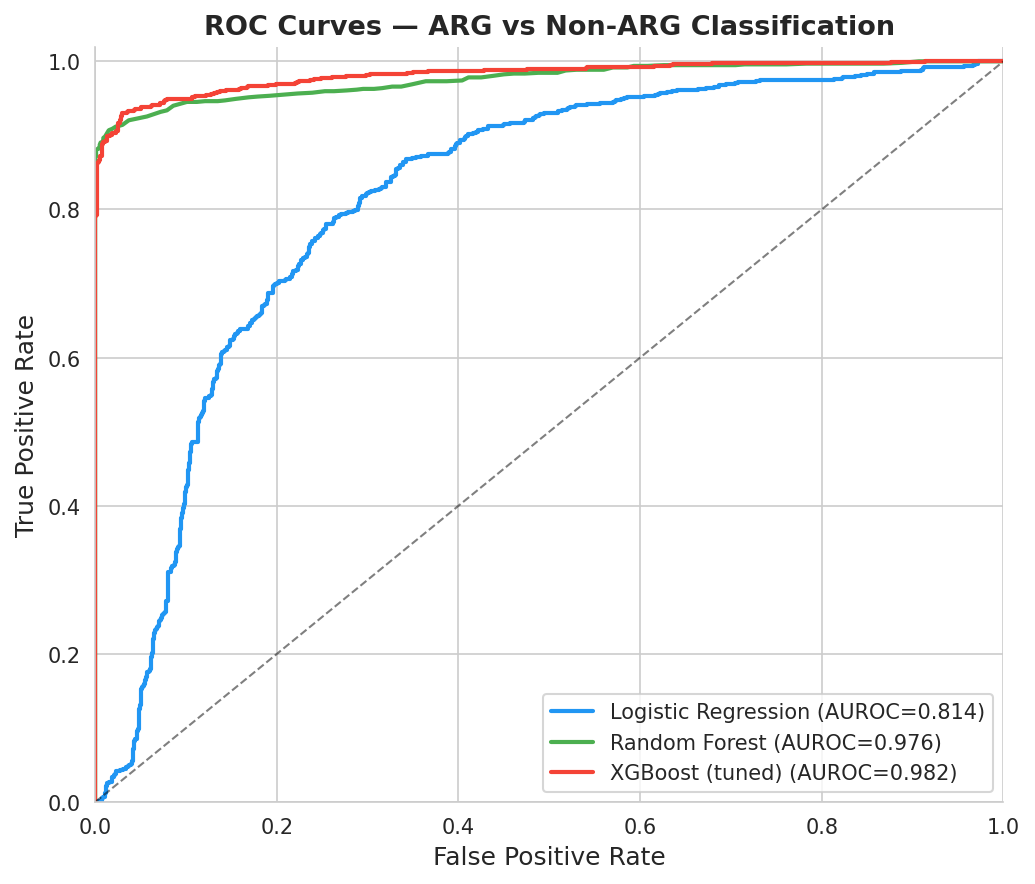

✓ Saved → /content/drive/MyDrive/ARG_Project/results/figures/fig_roc_curves.png


In [ ]:
# ── 4.6 Plot ROC curves (all 3 models) ────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 6))

colors = ["#2196F3", "#4CAF50", "#F44336"]
for res, color in zip(results, colors):
    fpr, tpr, _ = roc_curve(y_te, res["_y_prob"])
    ax.plot(fpr, tpr, color=color, lw=2,
            label=f"{res['Model']} (AUROC={res['AUROC']:.3f})")

ax.plot([0,1], [0,1], "k--", lw=1, alpha=0.5)
ax.set_xlabel("False Positive Rate", fontsize=12)
ax.set_ylabel("True Positive Rate", fontsize=12)
ax.set_title("ROC Curves — ARG vs Non-ARG Classification", fontsize=13, fontweight="bold")
ax.legend(loc="lower right", fontsize=10)
ax.set_xlim([0, 1]); ax.set_ylim([0, 1.02])
sns.despine()

plt.tight_layout()
plt.savefig(f"{FIGS}/fig_roc_curves.png", dpi=300, bbox_inches="tight")
plt.show()
print(f"✓ Saved → {FIGS}/fig_roc_curves.png")


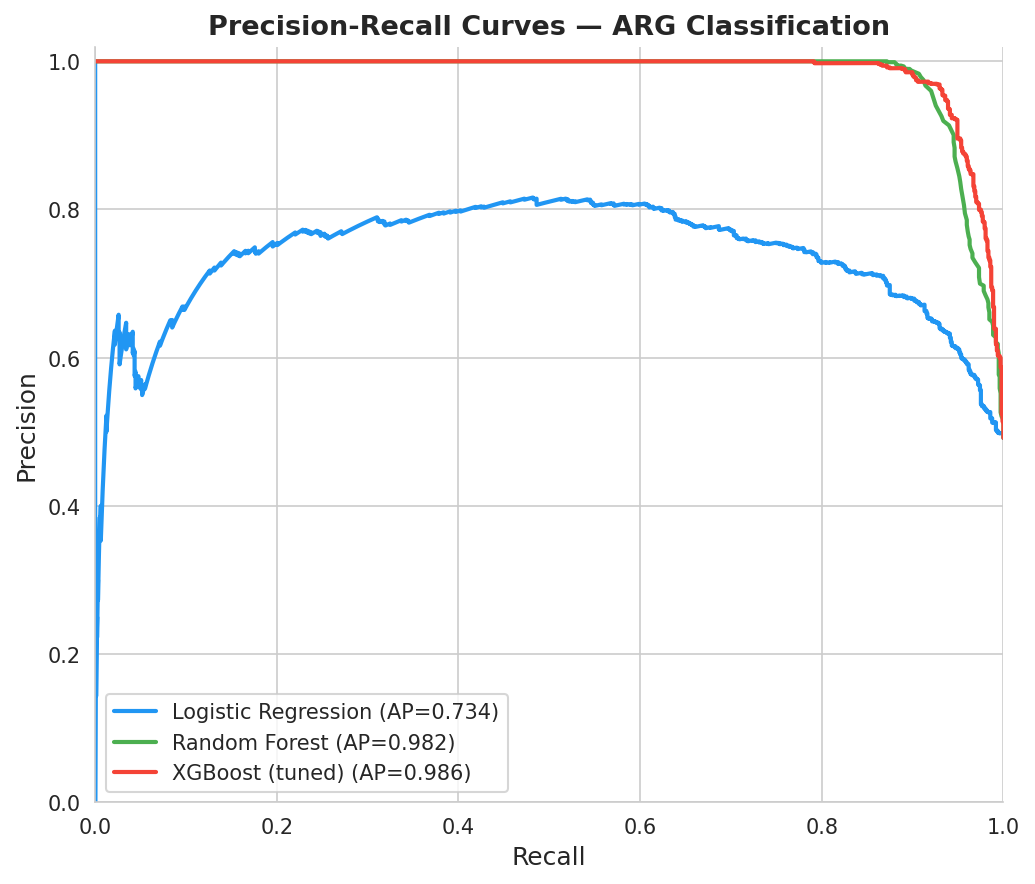

✓ Saved → /content/drive/MyDrive/ARG_Project/results/figures/fig_pr_curves.png


In [ ]:
# ── 4.7 Plot Precision-Recall curves ──────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 6))

colors = ["#2196F3", "#4CAF50", "#F44336"]
for res, color in zip(results, colors):
    prec, rec, _ = precision_recall_curve(y_te, res["_y_prob"])
    ax.plot(rec, prec, color=color, lw=2,
            label=f"{res['Model']} (AP={res['AP']:.3f})")

ax.set_xlabel("Recall", fontsize=12)
ax.set_ylabel("Precision", fontsize=12)
ax.set_title("Precision-Recall Curves — ARG Classification", fontsize=13, fontweight="bold")
ax.legend(loc="lower left", fontsize=10)
ax.set_xlim([0, 1]); ax.set_ylim([0, 1.02])
sns.despine()

plt.tight_layout()
plt.savefig(f"{FIGS}/fig_pr_curves.png", dpi=300, bbox_inches="tight")
plt.show()
print(f"✓ Saved → {FIGS}/fig_pr_curves.png")


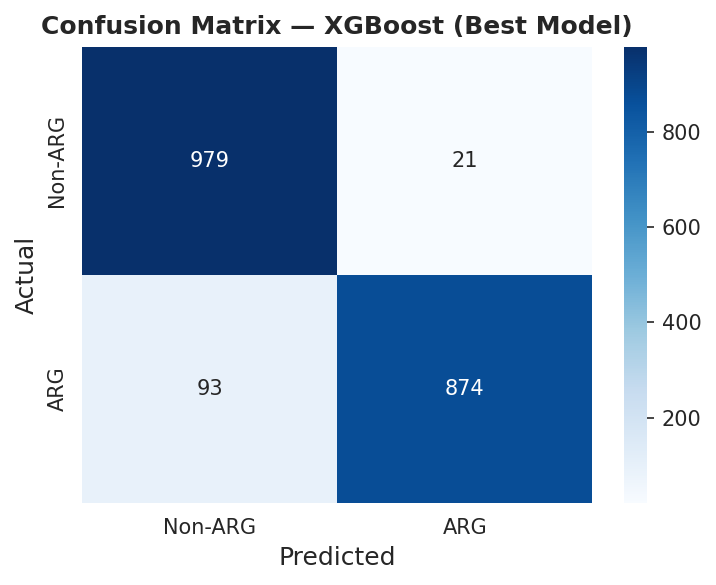

✓ Saved → /content/drive/MyDrive/ARG_Project/results/figures/fig_confusion_matrix.png


In [ ]:
# ── 4.8 Confusion matrix for best model (XGBoost) ─────────────────────────────
cm = confusion_matrix(y_te, results[2]["_y_pred"])
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Non-ARG","ARG"],
            yticklabels=["Non-ARG","ARG"], ax=ax)
ax.set_xlabel("Predicted", fontsize=12)
ax.set_ylabel("Actual", fontsize=12)
ax.set_title("Confusion Matrix — XGBoost (Best Model)", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{FIGS}/fig_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()
print(f"✓ Saved → {FIGS}/fig_confusion_matrix.png")


In [ ]:
# ── 4.9 Per-gene-family breakdown using CARD ARO metadata ─────────────────────
# Extracts resistance gene family from CARD headers and checks whether
# classification accuracy differs systematically by resistance mechanism class.

# Define missing feature path variables
FEAT_CARD = f"{FEAT}/features_card_positive.csv"
FEAT_SP = f"{FEAT}/features_swissprot_negative.csv"
FEAT_TRAIN_Y = f"{FEAT}/y_train.csv"

# Reload full combined dataframe with seq_id to recover CARD headers
df_card_full = pd.read_csv(FEAT_CARD)   # has seq_id column with full CARD header
df_sp_full   = pd.read_csv(FEAT_SP)

df_all_ids = pd.concat([df_card_full[["seq_id"]], df_sp_full[["seq_id"]]], ignore_index=True)

# Recover the same train/test split indices used in 4.1
# (must use the same random_state and stratify target for alignment)
y_full = pd.read_csv(FEAT_TRAIN_Y).squeeze().values
idx_all = np.arange(len(y_full))
idx_tr, idx_te = train_test_split(
    idx_all, test_size=0.2, random_state=SEED, stratify=y_full
)

test_ids    = df_all_ids.iloc[idx_te]["seq_id"].values
y_true_test = y_te
y_pred_test = results[2]["_y_pred"]   # XGBoost predictions from 4.5

# Extract gene name from CARD header format: gb|ACCESSION|ARO:NNNNNNN|GENE_NAME
def extract_gene_family(seq_id):
    if not seq_id.startswith("gb|") and "ARO:" not in str(seq_id):
        return "non-ARG (Swiss-Prot)"
    parts = str(seq_id).split("|")
    if len(parts) >= 4:
        gene_name = parts[3]
        # Group by common resistance mechanism prefixes
        gene_upper = gene_name.upper()
        if any(k in gene_upper for k in ["BLA", "AMPC", "OXA", "KPC", "NDM", "CTX", "SHV", "TEM"]):
            return "Beta-lactamase"
        elif any(k in gene_upper for k in ["AAC", "APH", "ANT"]):
            return "Aminoglycoside-modifying enzyme"
        elif any(k in gene_upper for k in ["TET"]):
            return "Tetracycline resistance"
        elif any(k in gene_upper for k in ["MEX", "ACR", "OQX", "ADE", "MDS", "MTR", "SME"]):
            return "Efflux pump component"
        elif any(k in gene_upper for k in ["ROB", "RPO"]):
            return "RNA polymerase target mutation"
        else:
            return "Other/unclassified ARG"
    return "Other/unclassified ARG"

families = pd.Series(test_ids).apply(extract_gene_family)

breakdown_df = pd.DataFrame({
    "seq_id": test_ids,
    "gene_family": families,
    "y_true": y_true_test,
    "y_pred": y_pred_test,
    "correct": (y_true_test == y_pred_test)
})

# Only look at true positives (actual ARGs) broken down by family
arg_breakdown = breakdown_df[breakdown_df["y_true"] == 1].groupby("gene_family").agg(
    n=("correct", "size"),
    accuracy=("correct", "mean")
).sort_values("n", ascending=False)

print("Classification accuracy by resistance gene family (test set ARGs only):")
print(arg_breakdown.to_string())

arg_breakdown.to_csv(f"{TABS}/gene_family_breakdown.csv")
print(f"\n✓ Saved → {TABS}/gene_family_breakdown.csv")

Classification accuracy by resistance gene family (test set ARGs only):
                                   n  accuracy
gene_family                                   
Other/unclassified ARG           555  0.875676
Beta-lactamase                   351  1.000000
Aminoglycoside-modifying enzyme   32  0.656250
Tetracycline resistance           15  0.666667
Efflux pump component             13  0.384615
RNA polymerase target mutation     1  1.000000

✓ Saved → /content/drive/MyDrive/ARG_Project/results/tables/gene_family_breakdown.csv


---
## Section 5 — Cross-Database Generalization
Test the best XGBoost model on ResFinder sequences at 90%, 70%, and 50% CD-HIT thresholds. This is the central result of the paper.

In [ ]:
# ── 5.1 Load ResFinder feature matrices ───────────────────────────────────────
X_resf = {}
for thr in [90, 70, 50]:
    path = f"{FEAT}/X_resfinder_{thr}.csv"
    if os.path.exists(path):
        X_resf[thr] = pd.read_csv(path).values
        print(f"✓ Loaded ResFinder {thr}%: {X_resf[thr].shape}")
    else:
        print(f"✗ Missing: {path}")


✓ Loaded ResFinder 90%: (100, 8005)
✓ Loaded ResFinder 70%: (66, 8005)
✓ Loaded ResFinder 50%: (40, 8005)


In [ ]:
# ── 5.2 Evaluate XGBoost on each ResFinder test set ───────────────────────────
# All ResFinder sequences are true ARGs → label = 1
# Metric: AUROC, F1 (treating all as positive vs model's negative predictions),
#         MCC, and Average Precision

crossdb_results = []

for thr in [90, 70, 50]:
    if thr not in X_resf:
        continue

    X_test_resf = X_resf[thr]
    # All are ARGs (positive class = 1)
    # We score them: a good model should assign high probability to all
    y_true_resf = np.ones(X_test_resf.shape[0], dtype=int)

    y_prob_resf = xgb_model.predict_proba(X_test_resf)[:, 1]
    y_pred_resf = xgb_model.predict(X_test_resf)

    # For a one-class test set, some metrics need care:
    # AUROC requires both classes → compute as "fraction above 0.5" threshold
    # We report: fraction classified as ARG, mean predicted probability,
    #            and the standard metrics where applicable

    frac_correct    = np.mean(y_pred_resf == 1)
    mean_prob       = np.mean(y_prob_resf)
    median_prob     = np.median(y_prob_resf)
    # AUROC is undefined for one-class — we report positive rate instead
    positive_rate   = frac_correct

    row = {
        "CD-HIT Threshold (%)" : thr,
        "N sequences"          : X_test_resf.shape[0],
        "Fraction classified as ARG" : round(frac_correct, 4),
        "Mean predicted probability" : round(mean_prob, 4),
        "Median predicted probability": round(median_prob, 4),
    }
    crossdb_results.append(row)
    print(f"ResFinder @ {thr}%:")
    print(f"  Sequences in test set       : {X_test_resf.shape[0]}")
    print(f"  Fraction classified as ARG  : {frac_correct:.4f} ({100*frac_correct:.1f}%)")
    print(f"  Mean predicted probability  : {mean_prob:.4f}")
    print(f"  Median predicted probability: {median_prob:.4f}")
    print()

crossdb_df = pd.DataFrame(crossdb_results)
crossdb_df.to_csv(f"{TABS}/crossdb_generalization.csv", index=False)
print(f"✓ Cross-DB results saved → {TABS}/crossdb_generalization.csv")
print("\n", crossdb_df.to_string(index=False))


ResFinder @ 90%:
  Sequences in test set       : 100
  Fraction classified as ARG  : 0.0000 (0.0%)
  Mean predicted probability  : 0.0120
  Median predicted probability: 0.0113

ResFinder @ 70%:
  Sequences in test set       : 66
  Fraction classified as ARG  : 0.0000 (0.0%)
  Mean predicted probability  : 0.0125
  Median predicted probability: 0.0124

ResFinder @ 50%:
  Sequences in test set       : 40
  Fraction classified as ARG  : 0.0000 (0.0%)
  Mean predicted probability  : 0.0125
  Median predicted probability: 0.0128

✓ Cross-DB results saved → /content/drive/MyDrive/ARG_Project/results/tables/crossdb_generalization.csv

  CD-HIT Threshold (%)  N sequences  Fraction classified as ARG  Mean predicted probability  Median predicted probability
                   90          100                         0.0                      0.0120                        0.0113
                   70           66                         0.0                      0.0125                        0.0124

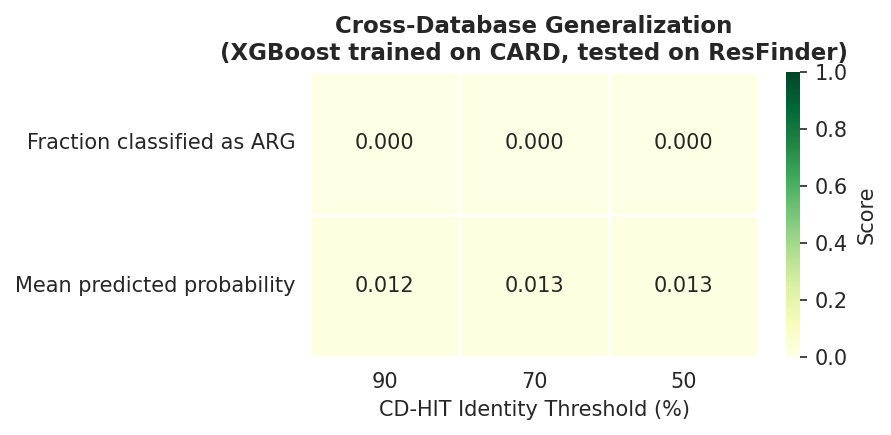

✓ Saved → /content/drive/MyDrive/ARG_Project/results/figures/fig_crossdb_heatmap.png


In [ ]:
# ── 5.3 Cross-DB summary heatmap ──────────────────────────────────────────────
plot_df = crossdb_df.set_index("CD-HIT Threshold (%)")[
    ["Fraction classified as ARG", "Mean predicted probability"]
].T

fig, ax = plt.subplots(figsize=(6, 3))
sns.heatmap(plot_df.astype(float), annot=True, fmt=".3f",
            cmap="YlGn", vmin=0.0, vmax=1.0,
            linewidths=0.5, ax=ax,
            cbar_kws={"label": "Score"})
ax.set_title("Cross-Database Generalization\n(XGBoost trained on CARD, tested on ResFinder)",
             fontsize=11, fontweight="bold")
ax.set_xlabel("CD-HIT Identity Threshold (%)", fontsize=10)
plt.tight_layout()
plt.savefig(f"{FIGS}/fig_crossdb_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()
print(f"✓ Saved → {FIGS}/fig_crossdb_heatmap.png")


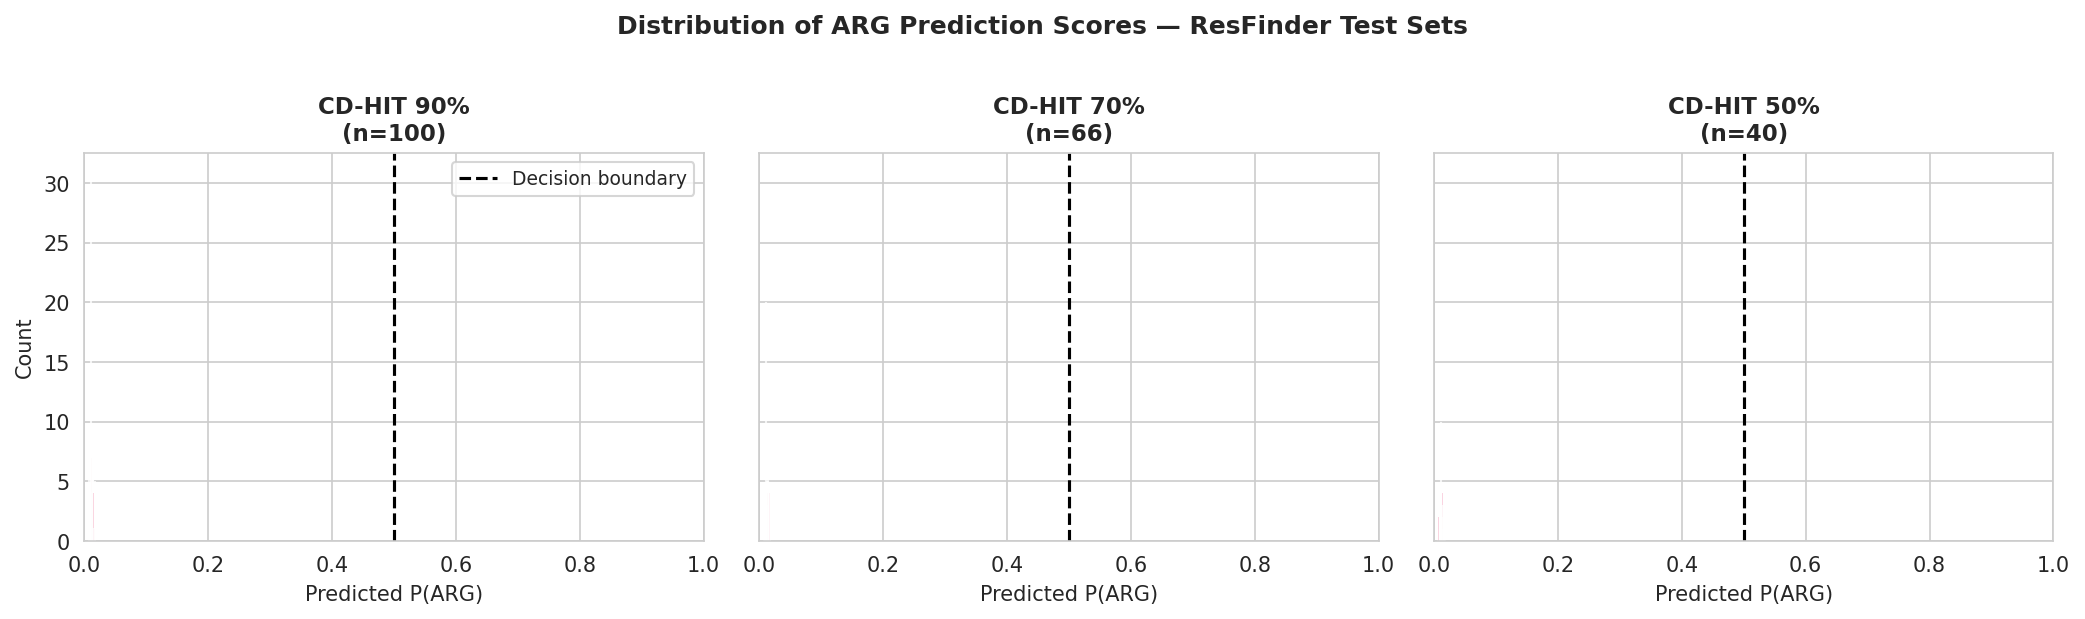

✓ Saved → /content/drive/MyDrive/ARG_Project/results/figures/fig_crossdb_prob_dist.png


In [ ]:
# ── 5.4 Predicted probability distributions across thresholds ─────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)

for ax, thr in zip(axes, [90, 70, 50]):
    if thr not in X_resf:
        ax.set_visible(False)
        continue
    probs = xgb_model.predict_proba(X_resf[thr])[:, 1]
    ax.hist(probs, bins=30, color="#E91E63", alpha=0.75, edgecolor="white")
    ax.axvline(0.5, color="black", lw=1.5, linestyle="--", label="Decision boundary")
    ax.set_title(f"CD-HIT {thr}%\n(n={len(probs)})", fontsize=11, fontweight="bold")
    ax.set_xlabel("Predicted P(ARG)", fontsize=10)
    ax.set_xlim([0, 1])

axes[0].set_ylabel("Count", fontsize=10)
axes[0].legend(fontsize=9)

fig.suptitle("Distribution of ARG Prediction Scores — ResFinder Test Sets",
             fontsize=12, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(f"{FIGS}/fig_crossdb_prob_dist.png", dpi=300, bbox_inches="tight")
plt.show()
print(f"✓ Saved → {FIGS}/fig_crossdb_prob_dist.png")


---
## Section 6 — SHAP Interpretability
Identify which k-mers and physicochemical features drive ARG predictions.

In [ ]:
# ── 6.1 Compute SHAP values for XGBoost ───────────────────────────────────────
# Use the held-out test set (X_te)
# This takes ~5–10 minutes

FEAT_COLS = f"{FEAT}/selected_feature_columns.json"
SHAP_CKPT = f"{CKPT}/shap_values.npy"
FEAT_NAMES_CKPT = f"{CKPT}/shap_feature_names.json"

if os.path.exists(SHAP_CKPT):
    shap_values     = np.load(SHAP_CKPT)
    with open(FEAT_NAMES_CKPT) as f:
        feature_names = json.load(f)
    print(f"✓ Loaded cached SHAP values: {shap_values.shape}")
else:
    print("Computing SHAP values (TreeExplainer)...")
    # Load feature column names
    with open(FEAT_COLS) as f:
        feature_names = json.load(f)

    explainer   = shap.TreeExplainer(xgb_model)
    shap_values = explainer.shap_values(X_te)

    np.save(SHAP_CKPT, shap_values)
    with open(FEAT_NAMES_CKPT, "w") as f:
        json.dump(feature_names, f)
    print(f"✓ SHAP values computed and saved: {shap_values.shape}")

Computing SHAP values (TreeExplainer)...
✓ SHAP values computed and saved: (1967, 8005)


/tmp/ipykernel_1929/4271688188.py:3: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


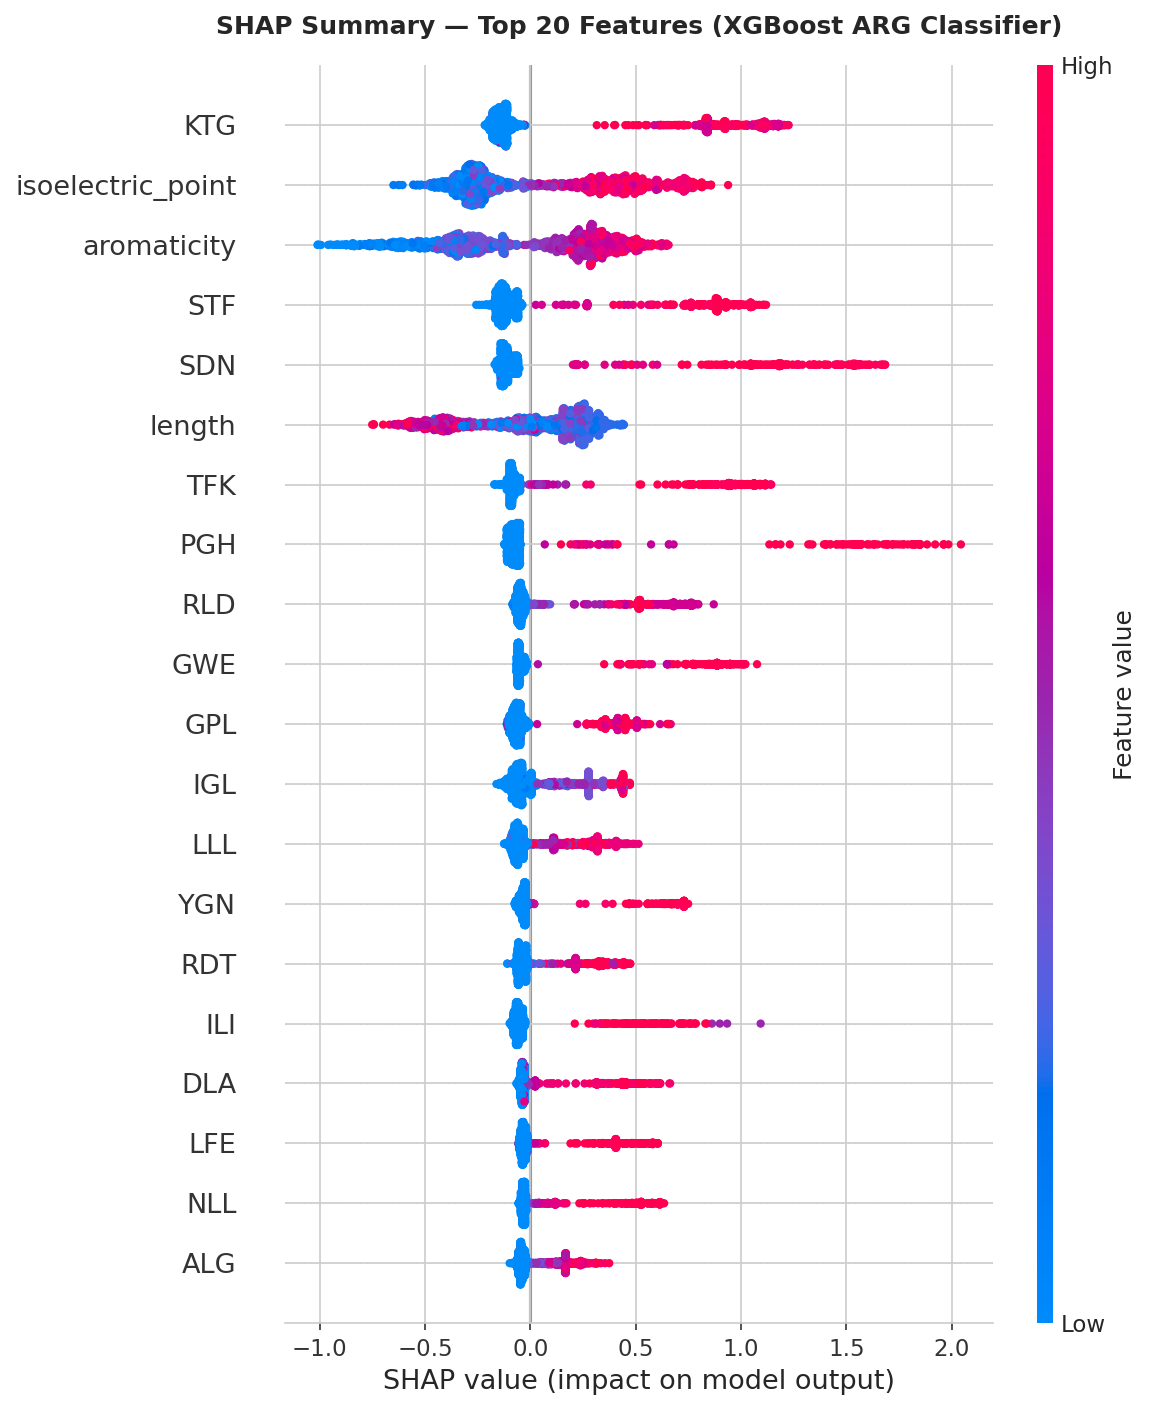

✓ Saved → /content/drive/MyDrive/ARG_Project/results/figures/fig_shap_summary.png


In [ ]:
# ── 6.2 SHAP summary plot (beeswarm) — top 20 features ────────────────────────
plt.figure(figsize=(10, 7))
shap.summary_plot(
    shap_values,
    X_te,
    feature_names=feature_names,
    max_display=20,
    show=False,
    plot_type="dot"
)
plt.title("SHAP Summary — Top 20 Features (XGBoost ARG Classifier)",
          fontsize=12, fontweight="bold", pad=15)
plt.tight_layout()
plt.savefig(f"{FIGS}/fig_shap_summary.png", dpi=300, bbox_inches="tight")
plt.show()
print(f"✓ Saved → {FIGS}/fig_shap_summary.png")


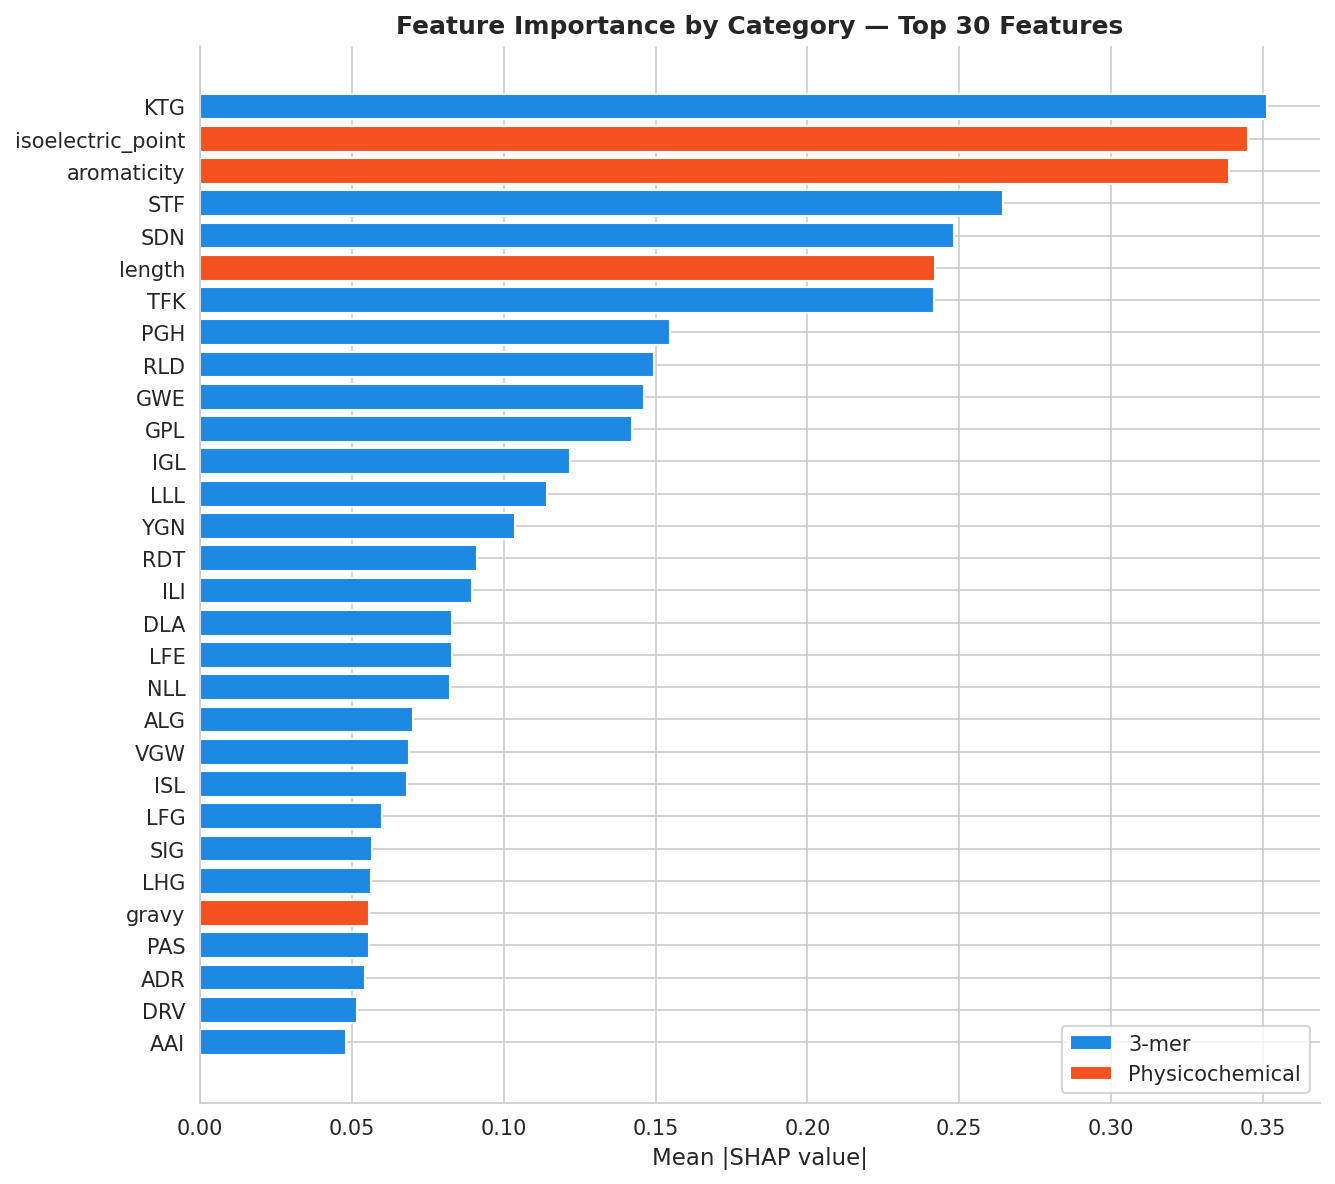

✓ Saved → /content/drive/MyDrive/ARG_Project/results/figures/fig_shap_bar_category.png


In [ ]:
# ── 6.3 SHAP bar plot — mean |SHAP| by feature category ───────────────────────
PHYS_COLS = ["length", "isoelectric_point", "aromaticity", "instability_index", "gravy"]

mean_abs_shap = np.abs(shap_values).mean(axis=0)
shap_df = pd.DataFrame({
    "feature"    : feature_names,
    "mean_abs_shap": mean_abs_shap
}).sort_values("mean_abs_shap", ascending=False)

# Tag as k-mer or physicochemical
phys_set = set(PHYS_COLS)
shap_df["category"] = shap_df["feature"].apply(
    lambda x: "Physicochemical" if x in phys_set else "3-mer"
)

# Top 30 features
top30 = shap_df.head(30)
palette = {"3-mer": "#1E88E5", "Physicochemical": "#F4511E"}

fig, ax = plt.subplots(figsize=(9, 8))
colors  = [palette[c] for c in top30["category"]]
ax.barh(top30["feature"][::-1], top30["mean_abs_shap"][::-1], color=colors[::-1])
ax.set_xlabel("Mean |SHAP value|", fontsize=11)
ax.set_title("Feature Importance by Category — Top 30 Features",
             fontsize=12, fontweight="bold")
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=v, label=k) for k, v in palette.items()]
ax.legend(handles=legend_elements, loc="lower right", fontsize=10)
sns.despine()
plt.tight_layout()
plt.savefig(f"{FIGS}/fig_shap_bar_category.png", dpi=300, bbox_inches="tight")
plt.show()
print(f"✓ Saved → {FIGS}/fig_shap_bar_category.png")

Top 3 k-mers by SHAP: ['KTG', 'STF', 'SDN']


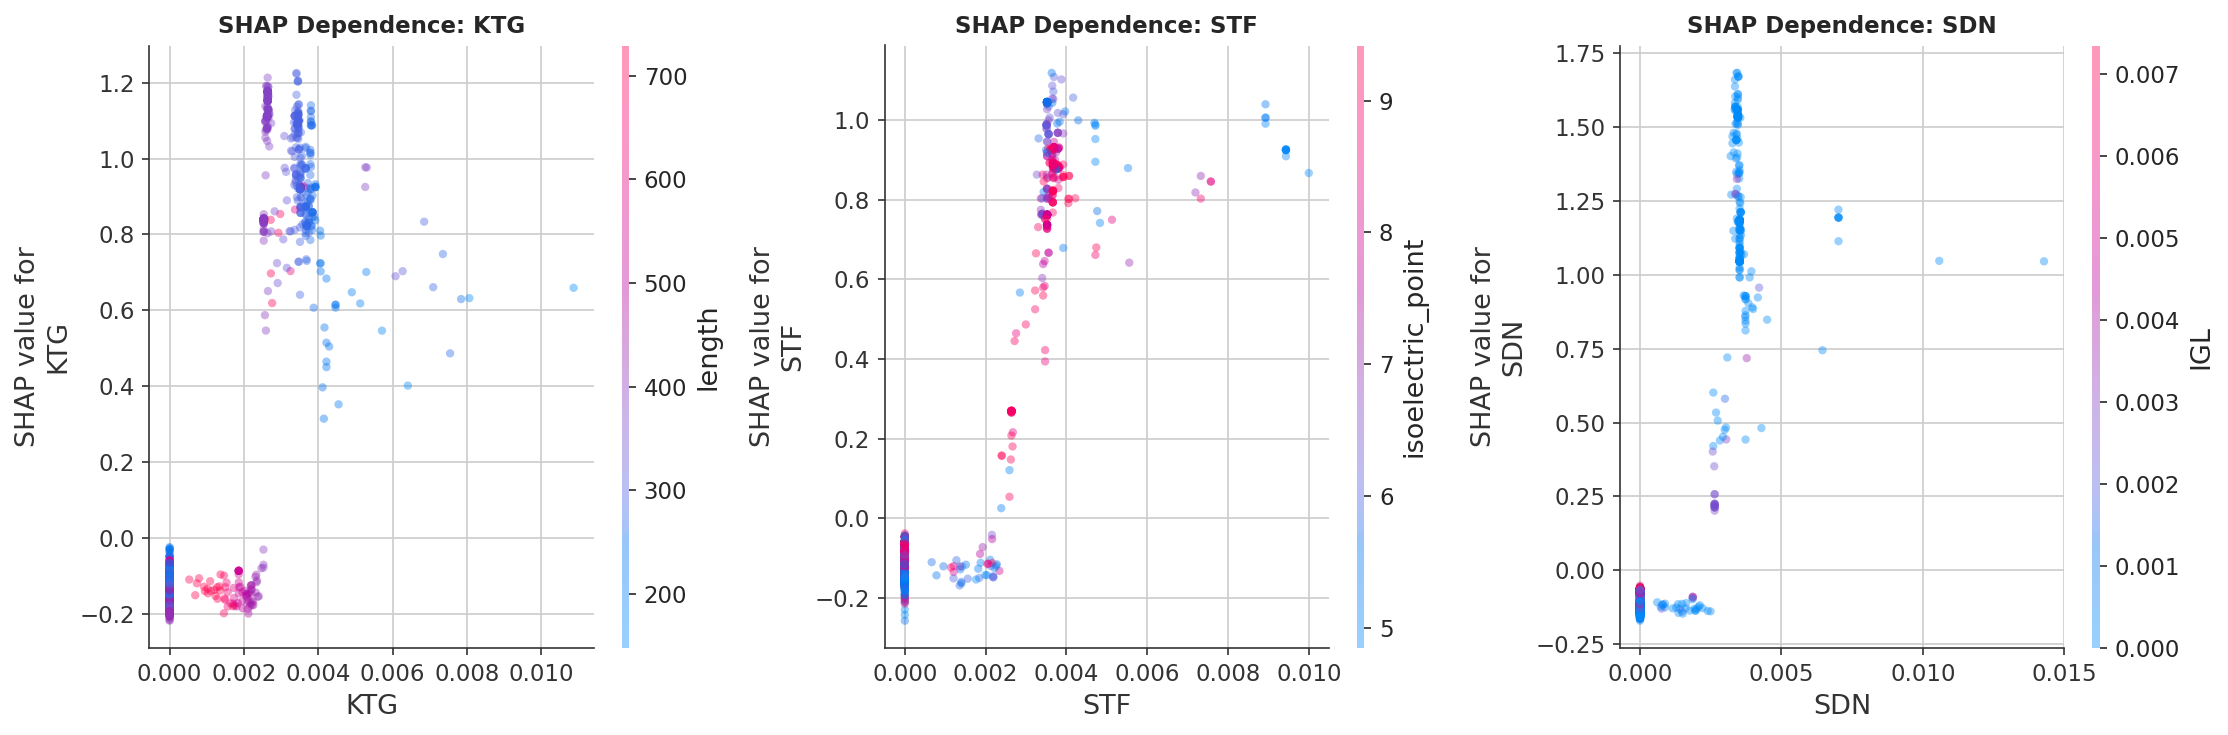

✓ Saved → /content/drive/MyDrive/ARG_Project/results/figures/fig_shap_dependence.png


In [ ]:
# ── 6.4 SHAP dependence plots — top 3 k-mers ──────────────────────────────────
top_kmers = shap_df[shap_df["category"] == "3-mer"]["feature"].head(3).tolist()
print(f"Top 3 k-mers by SHAP: {top_kmers}")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, kmer in zip(axes, top_kmers):
    idx = feature_names.index(kmer)
    shap.dependence_plot(
        idx, shap_values, X_te,
        feature_names=feature_names,
        ax=ax, show=False,
        alpha=0.4
    )
    ax.set_title(f"SHAP Dependence: {kmer}", fontsize=11, fontweight="bold")

plt.tight_layout()
plt.savefig(f"{FIGS}/fig_shap_dependence.png", dpi=300, bbox_inches="tight")
plt.show()
print(f"✓ Saved → {FIGS}/fig_shap_dependence.png")


In [ ]:
# ── 6.5 Biological annotation of top 10 k-mers ────────────────────────────────
# Amino acid property lookup
AA_PROPS = {
    "A": "nonpolar",    "C": "polar",       "D": "negative",
    "E": "negative",    "F": "aromatic",    "G": "nonpolar",
    "H": "positive",    "I": "nonpolar",    "K": "positive",
    "L": "nonpolar",    "M": "nonpolar",    "N": "polar",
    "P": "nonpolar",    "Q": "polar",       "R": "positive",
    "S": "polar",       "T": "polar",       "V": "nonpolar",
    "W": "aromatic",    "Y": "aromatic",
}

top10_kmers = shap_df[shap_df["category"] == "3-mer"]["feature"].head(10)

print(f"{'Rank':>5}  {'K-mer':>8}  {'Mean|SHAP|':>12}  {'AA Properties':>35}")
print("-" * 70)
for rank, (_, row) in enumerate(
        shap_df[shap_df["category"] == "3-mer"].head(10).iterrows(), 1):
    kmer = row["feature"]
    props = " | ".join(AA_PROPS.get(aa, "?") for aa in kmer)
    print(f"{rank:>5}  {kmer:>8}  {row['mean_abs_shap']:>12.5f}  {props:>35}")

shap_df.head(30).to_csv(f"{TABS}/shap_top30_features.csv", index=False)
print(f"\n✓ SHAP table saved → {TABS}/shap_top30_features.csv")


 Rank     K-mer    Mean|SHAP|                        AA Properties
----------------------------------------------------------------------
    1       KTG       0.35124          positive | polar | nonpolar
    2       STF       0.26429             polar | polar | aromatic
    3       SDN       0.24827             polar | negative | polar
    4       TFK       0.24184          polar | aromatic | positive
    5       PGH       0.15482       nonpolar | nonpolar | positive
    6       RLD       0.14951       positive | nonpolar | negative
    7       GWE       0.14610       nonpolar | aromatic | negative
    8       GPL       0.14215       nonpolar | nonpolar | nonpolar
    9       IGL       0.12176       nonpolar | nonpolar | nonpolar
   10       LLL       0.11438       nonpolar | nonpolar | nonpolar

✓ SHAP table saved → /content/drive/MyDrive/ARG_Project/results/tables/shap_top30_features.csv


---
## Section 7 — Dataset Statistics
Generate the dataset statistics table that goes in the paper (Table 0 / Methods section).

In [ ]:
# ── 7.1 Dataset statistics summary ────────────────────────────────────────────
# Ensure all paths are defined inside this scope
CARD_RAW = f"{RAW}/card_positive_raw.fasta"
CARD_5K  = f"{RAW}/card_positive_5000.fasta"
SP_POOL  = f"{RAW}/swissprot_negative_pool.fasta"
SP_NEG_5K = f"{PROC}/swissprot_negative_5000.fasta"
RESF_RAW = f"{RAW}/resfinder_raw.fasta"

def seq_stats(fasta_path):
    if not os.path.exists(fasta_path):
        return {"n": "N/A", "mean_len": "N/A", "min_len": "N/A", "max_len": "N/A"}
    recs   = list(SeqIO.parse(fasta_path, "fasta"))
    lens   = [len(r.seq) for r in recs]
    return {
        "n"       : len(recs),
        "mean_len": round(np.mean(lens), 1),
        "min_len" : min(lens),
        "max_len" : max(lens),
    }

datasets = {
    "CARD (raw download)"            : CARD_RAW,
    "CARD (filtered + sampled)"      : CARD_5K,
    "Swiss-Prot pool (raw)"          : SP_POOL,
    "Swiss-Prot negatives (filtered)": SP_NEG_5K,
    "ResFinder (raw)"                : RESF_RAW,
    "ResFinder test (90% CD-HIT)"    : f"{PROC}/resfinder_test_90.fasta",
    "ResFinder test (70% CD-HIT)"    : f"{PROC}/resfinder_test_70.fasta",
    "ResFinder test (50% CD-HIT)"    : f"{PROC}/resfinder_test_50.fasta",
}

rows = []
for label, path in datasets.items():
    s = seq_stats(path)
    rows.append({"Dataset": label, **s})

stats_df = pd.DataFrame(rows)
stats_df.to_csv(f"{TABS}/dataset_statistics.csv", index=False)
print(stats_df.to_string(index=False))
print(f"\n✓ Saved → {TABS}/dataset_statistics.csv")

                        Dataset    n  mean_len  min_len  max_len
            CARD (raw download) 4840     320.6       53     1452
      CARD (filtered + sampled) 4835     320.4       53     1452
          Swiss-Prot pool (raw) 9424     421.8       50     1963
Swiss-Prot negatives (filtered) 5000     421.6       50     1962
                ResFinder (raw) 3164     909.7      237     1998
    ResFinder test (90% CD-HIT)  100     923.6      237     1998
    ResFinder test (70% CD-HIT)   66     908.0      387     1746
    ResFinder test (50% CD-HIT)   40     884.2      387     1746

✓ Saved → /content/drive/MyDrive/ARG_Project/results/tables/dataset_statistics.csv


---
## Section 8 — Final Checkpoint
Verify all outputs and print a full summary.

In [ ]:
# ── 8.1 Verify all output files ───────────────────────────────────────────────
import glob

print("=" * 60)
print("FINAL CHECKPOINT — All Output Files")
print("=" * 60)

sections = {
    "Raw Data"      : RAW,
    "Processed Data": PROC,
    "Features"      : FEAT,
    "Models"        : CKPT,
    "Figures"       : FIGS,
    "Tables"        : TABS,
}

total_files = 0
for label, folder in sections.items():
    files = sorted(glob.glob(f"{folder}/*"))
    files = [f for f in files if os.path.isfile(f)]
    total_files += len(files)
    print(f"\n{label} ({folder}):")
    for fpath in files:
        size_kb = os.path.getsize(fpath) // 1024
        print(f"  {os.path.basename(fpath):45s}  {size_kb:6d} KB")

print(f"\n{'─'*60}")
print(f"Total files: {total_files}")


FINAL CHECKPOINT — All Output Files

Raw Data (/content/drive/MyDrive/ARG_Project/data/raw):
  card_data.tar.bz2                                3914 KB
  card_positive_5000.fasta                         1839 KB
  card_positive_raw.fasta                          1824 KB
  nucleotide_fasta_protein_homolog_model.fasta     4910 KB
  nucleotide_fasta_protein_knockout_model.fasta      19 KB
  nucleotide_fasta_protein_overexpression_model.fasta      11 KB
  nucleotide_fasta_protein_variant_model.fasta      344 KB
  nucleotide_fasta_rRNA_gene_variant_model.fasta     182 KB
  protein_fasta_protein_homolog_model.fasta        1824 KB
  protein_fasta_protein_knockout_model.fasta          7 KB
  protein_fasta_protein_overexpression_model.fasta       4 KB
  protein_fasta_protein_variant_model.fasta         123 KB
  resfinder_raw.fasta                              2925 KB
  swissprot_negative_pool.fasta                    5181 KB

Processed Data (/content/drive/MyDrive/ARG_Project/data/processed):
  

In [ ]:
# ── 8.2 Final results summary ─────────────────────────────────────────────────
print("=" * 60)
print("RESULTS SUMMARY")
print("=" * 60)

print("\n── In-distribution performance (held-out test set) ───────")
print(metrics_df.to_string(index=False))

print("\n── Cross-database generalization (CARD → ResFinder) ──────")
print(crossdb_df.to_string(index=False))

print("\n── Top 5 features by SHAP importance ─────────────────────")
print(shap_df.head(5)[["feature","category","mean_abs_shap"]].to_string(index=False))

print("\n── Feature matrix dimensions ──────────────────────────────")
print(f"  Training features : {X_tr.shape[1]} total")
print(f"  Training samples  : {X_tr.shape[0]} (train) + {X_te.shape[0]} (test)")
print(f"  Positive class    : CARD ARG sequences")
print(f"  Negative class    : Swiss-Prot reviewed bacterial proteins (BLAST-filtered)")

print("\n✓ Notebook complete. All outputs saved to Google Drive.")
print(f"  Drive path: {BASE}")


RESULTS SUMMARY

── In-distribution performance (held-out test set) ───────
              Model  AUROC     F1    MCC     AP
Logistic Regression 0.8140 0.7483 0.4979 0.7338
      Random Forest 0.9756 0.9324 0.8734 0.9816
    XGBoost (tuned) 0.9818 0.9419 0.8863 0.9858

── Cross-database generalization (CARD → ResFinder) ──────
 CD-HIT Threshold (%)  N sequences  Fraction classified as ARG  Mean predicted probability  Median predicted probability
                   90          100                         0.0                      0.0120                        0.0113
                   70           66                         0.0                      0.0125                        0.0124
                   50           40                         0.0                      0.0125                        0.0128

── Top 5 features by SHAP importance ─────────────────────
          feature        category  mean_abs_shap
              KTG           3-mer       0.351236
isoelectric_point Physicochemi

In [ ]:
import shutil

shutil.make_archive(
    "/content/drive/MyDrive/ARG_Project/ARG_results",  # output path
    "zip",
    "/content/drive/MyDrive/ARG_Project/results"       # folder to zip
)
print("Done → ARG_results.zip in your Drive root")

Done → ARG_results.zip in your Drive root
